# Formula 1 Podium Prediction — Milestone 1 Notebook

## Notebook Navigation

This notebook is organized as a complete data-to-model pipeline. Existing Person 1 and Person 2 work is left unchanged; the added structure below makes the notebook easier to navigate and defend.

### Data Preparation
1. [Data Cleaning & Auditing](#1-data-cleaning--auditing)
2. [Initial EDA](#2-initial-eda--dataset-overview)
3. [Missing Values & Sentinel Analysis](#3-missing-values-and-sentinel-analysis)
4. [Semantic Typing](#4-semantic-typing)
5. [Driver-Race Duplicate Check](#5-driver-race-duplicate-check)
6. [Primary Key Auditing](#6-primary-key-auditing)
7. [Foreign Key Auditing](#7-foreign-key-auditing)
8. [Post-Cleaning Verification](#8-post-cleaning-verification)

### Feature Engineering & Data Question
9. [Person 2 — Modeling Table, Feature Engineering, and Q2](#person-2--modeling-table-feature-engineering-and-q2)

### Person 4 — Neural Network, Ablation, XAI & Inference
10. [Part 4 Overview](#part-4--neural-network-ablation-xai--inference)
11. [Data Handoff & Validation](#41-data-handoff--validation)
12. [Feature Set](#42-final-feature-set)
13. [Chronological Split](#43-chronological-train--validation--test-split)
14. [Preprocessing](#44-preprocessing)
15. [Evaluation Strategy](#45-evaluation-strategy)
16. [Neural Network Trials](#46-neural-network-trials)
17. [Final Test Evaluation](#47-final-unseen-test-evaluation)
18. [Feature-Group Ablation](#48-feature-group-ablation)
19. [Permutation Importance](#49-permutation-importance)
20. [SHAP Explainability](#410-shap-explainability)
21. [Inference Function](#411-inference-function)
22. [Part 4 Conclusion](#412-part-4-conclusion)


In [107]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/races.csv
/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/constructor_results.csv
/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/drivers.csv
/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/constructors.csv
/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/lap_times.csv
/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/status.csv
/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/driver_standings.csv
/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/seasons.csv
/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/pit_stops.csv
/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/sprint_results.csv
/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020/constructor_standings.csv
/kaggle/input/datasets/rohanrao/formula

## 1. Data Cleaning & Auditing

We first load and inspect the raw Formula 1 tables before applying any cleaning.
Cleaning decisions will be based on issues identified through programmatic checks
and visualizations.

In [108]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

BASE_PATH = "/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020"

circuits_raw = pd.read_csv(f"{BASE_PATH}/circuits.csv")
constructors_raw = pd.read_csv(f"{BASE_PATH}/constructors.csv")
constructor_results_raw = pd.read_csv(f"{BASE_PATH}/constructor_results.csv")
constructor_standings_raw = pd.read_csv(f"{BASE_PATH}/constructor_standings.csv")
drivers_raw = pd.read_csv(f"{BASE_PATH}/drivers.csv")
driver_standings_raw = pd.read_csv(f"{BASE_PATH}/driver_standings.csv")
races_raw = pd.read_csv(f"{BASE_PATH}/races.csv")
results_raw = pd.read_csv(f"{BASE_PATH}/results.csv")
qualifying_raw = pd.read_csv(f"{BASE_PATH}/qualifying.csv")
lap_times_raw = pd.read_csv(f"{BASE_PATH}/lap_times.csv")
pit_stops_raw = pd.read_csv(f"{BASE_PATH}/pit_stops.csv")
sprint_results_raw = pd.read_csv(f"{BASE_PATH}/sprint_results.csv")
seasons_raw = pd.read_csv(f"{BASE_PATH}/seasons.csv")
status_raw = pd.read_csv(f"{BASE_PATH}/status.csv")

tables_raw = {
    "circuits": circuits_raw,
    "constructors": constructors_raw,
    "constructor_results": constructor_results_raw,
    "constructor_standings": constructor_standings_raw,
    "drivers": drivers_raw,
    "driver_standings": driver_standings_raw,
    "races": races_raw,
    "results": results_raw,
    "qualifying": qualifying_raw,
    "lap_times": lap_times_raw,
    "pit_stops": pit_stops_raw,
    "sprint_results": sprint_results_raw,
    "seasons": seasons_raw,
    "status": status_raw
}

print("Number of tables loaded:", len(tables_raw))

Number of tables loaded: 14


## 2. Initial EDA — Dataset Overview

We first inspect the size and structure of each table programmatically.
This helps us understand the scale and grain of the relational dataset before cleaning.

In [109]:
overview = []

for name, df in tables_raw.items():
    overview.append({
        "table": name,
        "rows": df.shape[0],
        "columns": df.shape[1],
        "duplicate_rows": df.duplicated().sum()
    })

overview_df = pd.DataFrame(overview).sort_values("rows", ascending=False)

overview_df

,table,rows,columns,duplicate_rows
9,lap_times,589081,6,0
5,driver_standings,34863,7,0
7,results,26759,18,0
3,constructor_standings,13391,7,0
2,constructor_results,12625,5,0
10,pit_stops,11371,7,0
8,qualifying,10494,9,0
6,races,1125,18,0
4,drivers,861,9,0
11,sprint_results,360,16,0


### Observation

No table contains exact duplicate rows.

However, this does not guarantee that the required modeling grain is valid. The `results` table must still be checked separately for repeated `(raceId, driverId)` combinations, since historical shared-drive cases can create multiple rows for the same driver in one race.

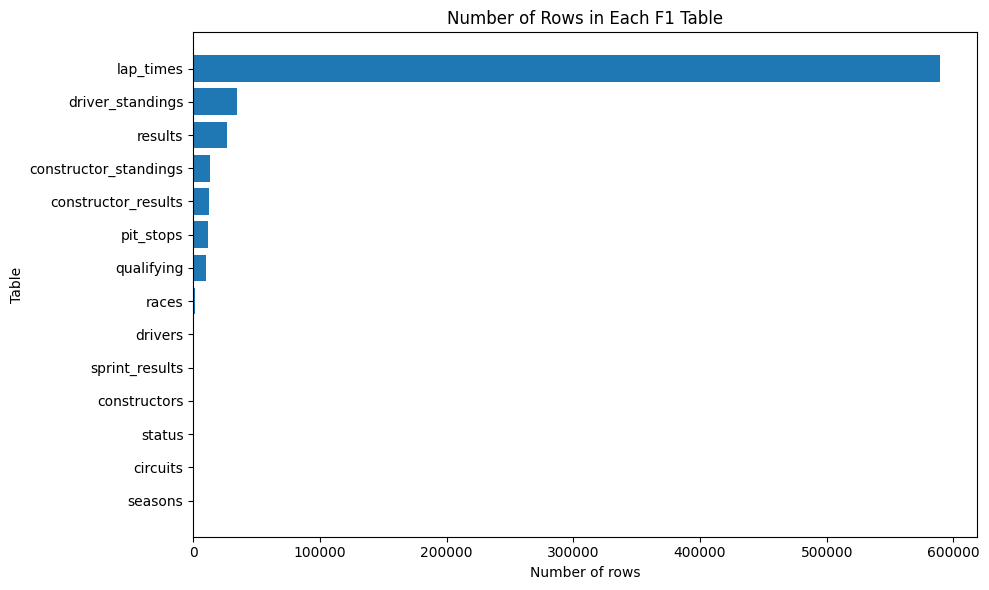

In [110]:
plt.figure(figsize=(10, 6))

plot_df = overview_df.sort_values("rows")

plt.barh(plot_df["table"], plot_df["rows"])

plt.xlabel("Number of rows")
plt.ylabel("Table")
plt.title("Number of Rows in Each F1 Table")

plt.tight_layout()
plt.show()

### Observation
The dataset contains tables with very different sizes and grains. For example, event-level tables such as lap times contain many more rows than lookup tables such as circuits or constructors.

Therefore, cleaning and duplicate checks should be performed according to the meaning and key structure of each table rather than applying the same rule to all tables.

## 3. Missing Values and Sentinel Analysis

The dataset uses the literal value `\N` as a placeholder for missing data.
We first identify where these sentinel values occur before cleaning so that the cleaning decision is based on observed missingness.

In [111]:
missing_summary = []

for name, df in tables_raw.items():
    for col in df.columns:
        sentinel_count = (df[col].astype(str) == r"\N").sum()

        if sentinel_count > 0:
            missing_summary.append({
                "table": name,
                "column": col,
                "sentinel_count": sentinel_count,
                "sentinel_pct": sentinel_count / len(df) * 100
            })

missing_summary_df = pd.DataFrame(missing_summary)

missing_summary_df.sort_values(
    "sentinel_pct",
    ascending=False
).head(30)

,table,column,sentinel_count,sentinel_pct
0,constructor_results,status,12608,99.865347
13,races,sprint_time,1110,98.666667
12,races,sprint_date,1107,98.400000
9,races,fp3_time,1072,95.288889
7,races,fp2_time,1057,93.955556
5,races,fp1_time,1057,93.955556
11,races,quali_time,1057,93.955556
8,races,fp3_date,1053,93.600000
1,drivers,number,802,93.147503
4,races,fp1_date,1035,92.000000


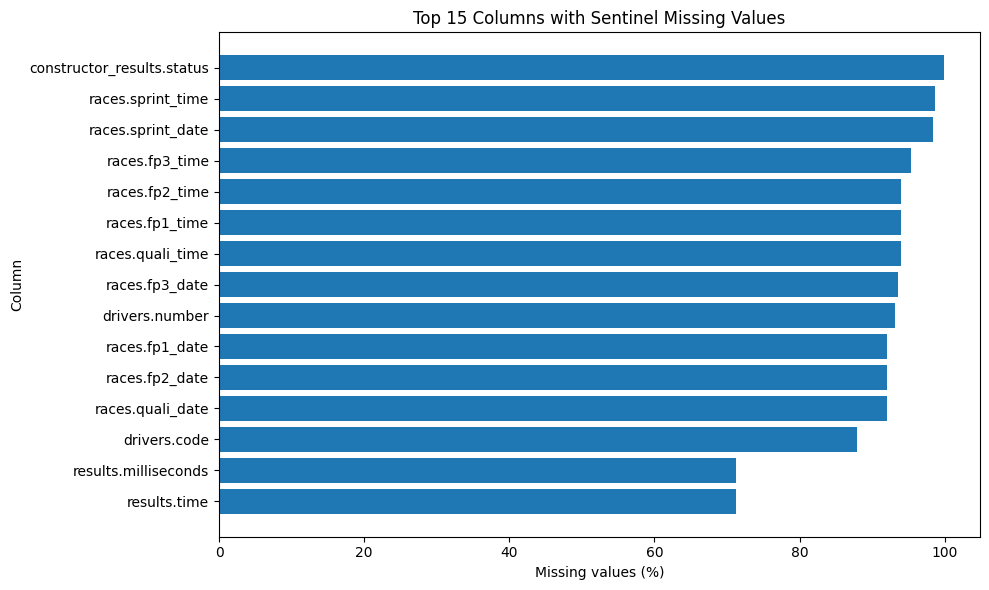

In [112]:
top_missing = (
    missing_summary_df
    .sort_values("sentinel_pct", ascending=False)
    .head(15)
    .copy()
)

top_missing["label"] = top_missing["table"] + "." + top_missing["column"]

plt.figure(figsize=(10, 6))

plt.barh(
    top_missing["label"][::-1],
    top_missing["sentinel_pct"][::-1]
)

plt.xlabel("Missing values (%)")
plt.ylabel("Column")
plt.title("Top 15 Columns with Sentinel Missing Values")

plt.tight_layout()
plt.show()

### Observation and Cleaning Decision

The amount of missing data differs across columns.

Some columns, such as `constructor_results.status` and several practice/sprint fields in `races`, have very high missingness, while others have moderate or low missingness.

Because the missing values have different meanings depending on the column, we will not apply one imputation method to every field.

At this cleaning stage, the literal `\N` sentinel values will be converted to proper missing values (`NaN`). Any later imputation or feature removal will be decided separately based on the meaning and usefulness of each feature.

In [113]:
tables_clean = {
    name: df.copy()
    for name, df in tables_raw.items()
}

for name, df in tables_clean.items():
    df.replace(r"\N", np.nan, inplace=True)

In [114]:
remaining_sentinels = 0

for name, df in tables_clean.items():
    remaining_sentinels += (df.astype(str) == r"\N").sum().sum()

print("Remaining literal \\N values:", remaining_sentinels)

Remaining literal \N values: 0


## 4. Semantic Typing

Some columns are stored as strings even though they represent dates or durations.
We convert them into appropriate data types so they can be processed correctly later.

In [115]:
date_columns = {
    "drivers": ["dob"],
    "races": ["date", "fp1_date", "fp2_date", "fp3_date", "quali_date", "sprint_date"]
}

for table_name, columns in date_columns.items():
    for col in columns:
        if col in tables_clean[table_name].columns:
            tables_clean[table_name][col] = pd.to_datetime(
                tables_clean[table_name][col],
                errors="coerce"
            )

In [116]:
print(tables_clean["drivers"]["dob"].dtype)
print(tables_clean["races"]["date"].dtype)

datetime64[ns]
datetime64[ns]


### Justification

Date columns are converted to `datetime` so they can be sorted, compared, and used in time-based analysis correctly.

`errors="coerce"` is used so invalid or unavailable dates become missing values instead of causing errors.

### Duration Conversion

Some timing columns are stored as strings such as `1:23.456`.
We convert them to numeric seconds so they can be analyzed and compared mathematically.

In [117]:
def time_to_seconds(value):
    if pd.isna(value):
        return np.nan

    parts = str(value).split(":")

    try:
        if len(parts) == 2:
            minutes, seconds = parts
            return float(minutes) * 60 + float(seconds)

        elif len(parts) == 3:
            hours, minutes, seconds = parts
            return (
                float(hours) * 3600
                + float(minutes) * 60
                + float(seconds)
            )

        else:
            return float(value)

    except ValueError:
        return np.nan

In [118]:
tables_clean["qualifying"]["q1_seconds"] = (
    tables_clean["qualifying"]["q1"].apply(time_to_seconds)
)

tables_clean["qualifying"]["q2_seconds"] = (
    tables_clean["qualifying"]["q2"].apply(time_to_seconds)
)

tables_clean["qualifying"]["q3_seconds"] = (
    tables_clean["qualifying"]["q3"].apply(time_to_seconds)
)

tables_clean["lap_times"]["time_seconds"] = (
    tables_clean["lap_times"]["time"].apply(time_to_seconds)
)

tables_clean["pit_stops"]["duration_seconds"] = (
    tables_clean["pit_stops"]["duration"].apply(time_to_seconds)
)

In [119]:
tables_clean["qualifying"][
    ["q1", "q1_seconds", "q2", "q2_seconds", "q3", "q3_seconds"]
].head(10)

,q1,q1_seconds,q2,q2_seconds,q3,q3_seconds
0,1:26.572,86.572,1:25.187,85.187,1:26.714,86.714
1,1:26.103,86.103,1:25.315,85.315,1:26.869,86.869
2,1:25.664,85.664,1:25.452,85.452,1:27.079,87.079
3,1:25.994,85.994,1:25.691,85.691,1:27.178,87.178
4,1:25.960,85.960,1:25.518,85.518,1:27.236,87.236
5,1:26.427,86.427,1:26.101,86.101,1:28.527,88.527
6,1:26.295,86.295,1:26.059,86.059,1:28.687,88.687
7,1:26.381,86.381,1:26.063,86.063,1:29.041,89.041
8,1:26.919,86.919,1:26.164,86.164,1:29.593,89.593
9,1:26.702,86.702,1:25.842,85.842,NaN,NaN


### Observation

The qualifying time strings were successfully converted to numeric seconds while missing values remained as `NaN`.

This makes the timing data easier to compare and use in later numerical analysis without inventing values for missing sessions.

## 5. Driver-Race Duplicate Check

The final modeling table must contain one row for each driver in each race. Therefore, we check whether the combination `(raceId, driverId)` is unique in the `results` table.

In [120]:
driver_race_counts = (
    tables_clean["results"]
    .groupby(["raceId", "driverId"])
    .size()
    .reset_index(name="count")
)

duplicate_driver_races = driver_race_counts[
    driver_race_counts["count"] > 1
]

print(
    "Number of duplicated driver-race combinations:",
    len(duplicate_driver_races)
)

duplicate_driver_races.head()

Number of duplicated driver-race combinations: 85


,raceId,driverId,count
13659,540,229,2
17821,717,373,2
18222,733,465,2
18445,742,475,2
18532,745,418,2


In [121]:
duplicate_details = (
    tables_clean["results"]
    .merge(
        duplicate_driver_races[["raceId", "driverId"]],
        on=["raceId", "driverId"],
        how="inner"
    )
    .merge(
        tables_clean["races"][["raceId", "year", "name"]],
        on="raceId",
        how="left"
    )
)

duplicate_by_year = (
    duplicate_details[
        ["year", "raceId", "driverId"]
    ]
    .drop_duplicates()
    .groupby("year")
    .size()
)

duplicate_by_year

year
1950     4
1951     4
1952     3
1953    14
1954    16
1955    15
1956    12
1957     8
1958     3
1960     1
1961     2
1962     1
1964     1
1978     1
dtype: int64

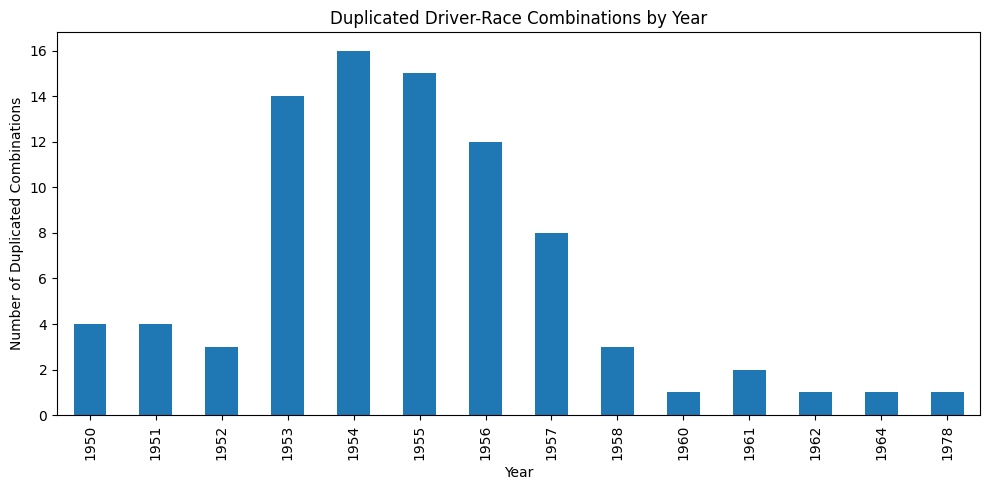

In [122]:
plt.figure(figsize=(10, 5))

duplicate_by_year.plot(kind="bar")

plt.title("Duplicated Driver-Race Combinations by Year")
plt.xlabel("Year")
plt.ylabel("Number of Duplicated Combinations")

plt.tight_layout()
plt.show()

### Observation

The duplicated driver-race combinations are concentrated mainly in the earlier Formula 1 seasons.

This matches the historical shared-drive issue, where a driver could appear more than once in the same race after switching cars.

Since the final modeling table requires one row per `(raceId, driverId)`, a consistent rule is needed to keep only one record for each duplicated pair.

### Duplicate Resolution Rule

Most duplicated `(raceId, driverId)` combinations occur in early Formula 1 seasons and are related to historical shared-drive cases.

To keep one row per driver and race without using post-race information, duplicates are resolved using the starting grid:

- Rows with a valid non-zero grid position are preferred.
- If multiple valid rows remain, the row with the lowest grid position is kept.
- `resultId` is used only as a tie-breaker.

`positionOrder` is not used for duplicate resolution because it is a post-race outcome and could introduce data leakage.

In [123]:
results_clean = tables_clean["results"].copy()

results_clean["valid_grid"] = results_clean["grid"] > 0

results_clean = (
    results_clean
    .sort_values(
        by=["raceId", "driverId", "valid_grid", "grid", "resultId"],
        ascending=[True, True, False, True, True]
    )
    .drop_duplicates(
        subset=["raceId", "driverId"],
        keep="first"
    )
    .drop(columns="valid_grid")
)

tables_clean["results"] = results_clean

In [124]:
remaining_duplicates = (
    tables_clean["results"]
    .duplicated(subset=["raceId", "driverId"])
    .sum()
)

print("Remaining duplicated driver-race combinations:", remaining_duplicates)
print("Rows before:", len(results_raw))
print("Rows after:", len(tables_clean["results"]))

Remaining duplicated driver-race combinations: 0
Rows before: 26759
Rows after: 26668


### Result

After applying the duplicate-resolution rule, no duplicated `(raceId, driverId)` combinations remain.

The `results` table decreased from 26,759 to 26,668 rows, giving one record per driver per race as required.

## 6. Primary Key Auditing

We verify that the expected primary key of each table is unique and contains no missing values.
For tables without a single identifier column, the appropriate composite key is checked.

In [125]:
primary_keys = {
    "circuits": ["circuitId"],
    "constructors": ["constructorId"],
    "constructor_results": ["constructorResultsId"],
    "constructor_standings": ["constructorStandingsId"],
    "drivers": ["driverId"],
    "driver_standings": ["driverStandingsId"],
    "races": ["raceId"],
    "results": ["resultId"],
    "qualifying": ["qualifyId"],
    "lap_times": ["raceId", "driverId", "lap"],
    "pit_stops": ["raceId", "driverId", "stop"],
    "sprint_results": ["resultId"],
    "seasons": ["year"],
    "status": ["statusId"]
}

pk_audit = []

for table_name, key_cols in primary_keys.items():
    df = tables_clean[table_name]

    missing_keys = df[key_cols].isna().any(axis=1).sum()
    duplicate_keys = df.duplicated(subset=key_cols).sum()

    pk_audit.append({
        "table": table_name,
        "key": ", ".join(key_cols),
        "missing_key_rows": missing_keys,
        "duplicate_key_rows": duplicate_keys
    })

pk_audit_df = pd.DataFrame(pk_audit)

pk_audit_df

,table,key,missing_key_rows,duplicate_key_rows
0,circuits,circuitId,0,0
1,constructors,constructorId,0,0
2,constructor_results,constructorResultsId,0,0
3,constructor_standings,constructorStandingsId,0,0
4,drivers,driverId,0,0
5,driver_standings,driverStandingsId,0,0
6,races,raceId,0,0
7,results,resultId,0,0
8,qualifying,qualifyId,0,0
9,lap_times,"raceId, driverId, lap",0,0


### Observation

All expected primary keys are complete and unique.

No table contains missing key values or duplicated primary/composite keys, so the key structure is internally consistent after cleaning.

## 7. Foreign Key Auditing

We check whether foreign-key values in child tables can be matched to the corresponding parent tables.

This verifies that the relational tables can be joined consistently without unmatched identifiers.

In [126]:
foreign_keys = [
    ("races", "circuitId", "circuits", "circuitId"),

    ("results", "raceId", "races", "raceId"),
    ("results", "driverId", "drivers", "driverId"),
    ("results", "constructorId", "constructors", "constructorId"),
    ("results", "statusId", "status", "statusId"),

    ("qualifying", "raceId", "races", "raceId"),
    ("qualifying", "driverId", "drivers", "driverId"),
    ("qualifying", "constructorId", "constructors", "constructorId"),

    ("lap_times", "raceId", "races", "raceId"),
    ("lap_times", "driverId", "drivers", "driverId"),

    ("pit_stops", "raceId", "races", "raceId"),
    ("pit_stops", "driverId", "drivers", "driverId"),

    ("driver_standings", "raceId", "races", "raceId"),
    ("driver_standings", "driverId", "drivers", "driverId"),

    ("constructor_results", "raceId", "races", "raceId"),
    ("constructor_results", "constructorId", "constructors", "constructorId"),

    ("constructor_standings", "raceId", "races", "raceId"),
    ("constructor_standings", "constructorId", "constructors", "constructorId"),

    ("sprint_results", "raceId", "races", "raceId"),
    ("sprint_results", "driverId", "drivers", "driverId"),
    ("sprint_results", "constructorId", "constructors", "constructorId"),
    ("sprint_results", "statusId", "status", "statusId")
]

fk_audit = []

for child_table, child_col, parent_table, parent_col in foreign_keys:
    child_values = tables_clean[child_table][child_col]
    parent_values = tables_clean[parent_table][parent_col]

    unmatched = (
        child_values.notna()
        & ~child_values.isin(parent_values)
    ).sum()

    fk_audit.append({
        "child_table": child_table,
        "foreign_key": child_col,
        "parent_table": parent_table,
        "parent_key": parent_col,
        "unmatched_rows": unmatched
    })

fk_audit_df = pd.DataFrame(fk_audit)

fk_audit_df

,child_table,foreign_key,parent_table,parent_key,unmatched_rows
0,races,circuitId,circuits,circuitId,0
1,results,raceId,races,raceId,0
2,results,driverId,drivers,driverId,0
3,results,constructorId,constructors,constructorId,0
4,results,statusId,status,statusId,0
5,qualifying,raceId,races,raceId,0
6,qualifying,driverId,drivers,driverId,0
7,qualifying,constructorId,constructors,constructorId,0
8,lap_times,raceId,races,raceId,0
9,lap_times,driverId,drivers,driverId,0


### Observation

All checked foreign keys successfully match their corresponding parent-table keys.

No unmatched foreign-key values were found, which indicates that the relational links between the cleaned tables are consistent.

## 8. Post-Cleaning Verification

After cleaning, we verify that the main data-quality issues identified earlier have been resolved.

In [127]:
before_after = pd.DataFrame({
    "check": [
        "Literal sentinel values",
        "Duplicated (raceId, driverId)"
    ],
    "before": [
        sum(
            (df.astype(str) == r"\N").sum().sum()
            for df in tables_raw.values()
        ),
        85
    ],
    "after": [
        sum(
            (df.astype(str) == r"\N").sum().sum()
            for df in tables_clean.values()
        ),
        tables_clean["results"]
        .duplicated(subset=["raceId", "driverId"])
        .sum()
    ]
})

before_after

,check,before,after
0,Literal sentinel values,160076,0
1,"Duplicated (raceId, driverId)",85,0


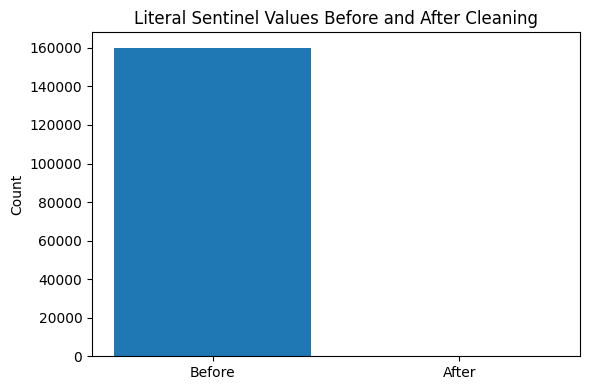

In [128]:
plt.figure(figsize=(6, 4))

plt.bar(
    ["Before", "After"],
    [before_after.loc[0, "before"], before_after.loc[0, "after"]]
)

plt.ylabel("Count")
plt.title("Literal Sentinel Values Before and After Cleaning")

plt.tight_layout()
plt.show()

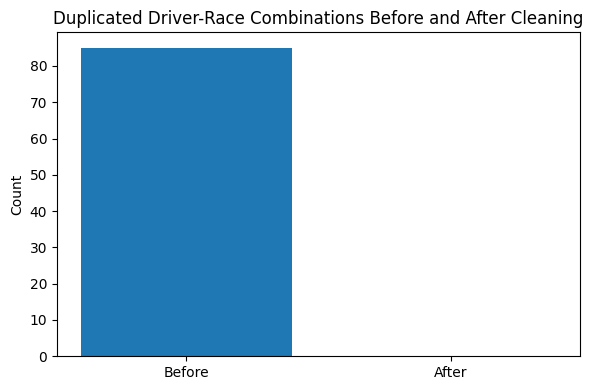

In [129]:
plt.figure(figsize=(6, 4))

plt.bar(
    ["Before", "After"],
    [before_after.loc[1, "before"], before_after.loc[1, "after"]]
)

plt.ylabel("Count")
plt.title("Duplicated Driver-Race Combinations Before and After Cleaning")

plt.tight_layout()
plt.show()

### Final Cleaning Result

The literal `\N` sentinel values were successfully converted to proper missing values.

The duplicated `(raceId, driverId)` combinations were also resolved, leaving one row per driver per race.

Primary-key and foreign-key audits showed no remaining integrity problems in the checked tables.

### Cleaned Dataset Summary

The following tables are now ready for the next stages of analysis and feature engineering.

In [130]:
clean_summary = []

for name, df in tables_clean.items():
    clean_summary.append({
        "table": name,
        "rows": df.shape[0],
        "columns": df.shape[1]
    })

clean_summary_df = pd.DataFrame(clean_summary).sort_values(
    "rows",
    ascending=False
)

clean_summary_df

,table,rows,columns
9,lap_times,589081,7
5,driver_standings,34863,7
7,results,26668,18
3,constructor_standings,13391,7
2,constructor_results,12625,5
10,pit_stops,11371,8
8,qualifying,10494,12
6,races,1125,18
4,drivers,861,9
11,sprint_results,360,16


## Person 2 — Modeling Table, Feature Engineering, and Q2



In [131]:
import re
import unicodedata

In [132]:
ALLOWED_FEATURES = [
    "year", "circuitId", "grid_position", "qualifying_position", "is_home_race",
    "driver_prior_starts", "driver_prior_podium_rate", "driver_prior_mean_finish",
    "constructor_prior_podium_rate", "constructor_prior_mean_points",
    "driver_circuit_prior_starts", "driver_circuit_prior_podium_rate",
    "driver_prior_standing_points", "driver_prior_standing_position",
    "constructor_prior_standing_points", "constructor_prior_standing_position",
]


In [133]:
COUNTRY_ALIASES = {
    "american": "united states", "argentine": "argentina", "argentinian": "argentina",
    "australian": "australia", "austrian": "austria", "belgian": "belgium",
    "british": "united kingdom", "brazilian": "brazil", "canadian": "canada",
    "dutch": "netherlands", "finnish": "finland", "french": "france",
    "german": "germany", "italian": "italy", "japanese": "japan",
    "mexican": "mexico", "monacan": "monaco", "monegasque": "monaco",
    "new zealander": "new zealand", "portuguese": "portugal", "russian": "russia",
    "south african": "south africa", "spanish": "spain", "swedish": "sweden",
    "swiss": "switzerland", "thai": "thailand", "uk": "united kingdom",
    "great britain": "united kingdom", "britain": "united kingdom",
    "usa": "united states", "u.s.a.": "united states",
    "united states of america": "united states", "republic of korea": "south korea",
    "korea": "south korea", "czechia": "czech republic", "uae": "united arab emirates",
}

def canonical_country(value):
    if pd.isna(value):
        return None
    value = unicodedata.normalize("NFKD", str(value))
    value = "".join(char for char in value if not unicodedata.combining(char))
    value = re.sub(r"\s+", " ", value.casefold().strip()).strip(" .")
    return COUNTRY_ALIASES.get(value, value) or None

def prior_history(entries, keys, prefix):
    grouped = entries.groupby(keys + ["race_order"], as_index=False, dropna=False).agg(
        starts=("podium", "size"), podiums=("podium", "sum"),
        finish_sum=("finish_position", "sum"), finish_count=("finish_position", "count"),
        points=("points", "sum"),
    ).sort_values(keys + ["race_order"], kind="stable")
    by_entity = grouped.groupby(keys, sort=False, dropna=False)
    grouped[f"{prefix}_prior_starts"] = by_entity["starts"].cumsum() - grouped["starts"]
    prior_podiums = by_entity["podiums"].cumsum() - grouped["podiums"]
    prior_finish_sum = by_entity["finish_sum"].cumsum() - grouped["finish_sum"]
    prior_finish_count = by_entity["finish_count"].cumsum() - grouped["finish_count"]
    prior_points = by_entity["points"].cumsum() - grouped["points"]
    prior_races = by_entity.cumcount()
    grouped[f"{prefix}_podium_rate"] = prior_podiums / grouped[f"{prefix}_prior_starts"].replace(0, np.nan)
    grouped[f"{prefix}_mean_finish"] = prior_finish_sum / prior_finish_count.replace(0, np.nan)
    grouped[f"{prefix}_mean_points"] = prior_points / prior_races.replace(0, np.nan).to_numpy()
    return grouped

def lag_standings(frame, entity, prefix, race_order):
    frame = frame.merge(race_order, on="raceId", how="left", validate="many_to_one").copy()
    frame["points"] = pd.to_numeric(frame["points"], errors="coerce")
    frame["position"] = pd.to_numeric(frame["position"], errors="coerce")
    frame = frame.sort_values(["race_order", entity], kind="stable")
    by_entity = frame.groupby(entity, sort=False)
    frame[f"{prefix}_prior_standing_points"] = by_entity["points"].shift(1)
    frame[f"{prefix}_prior_standing_position"] = by_entity["position"].shift(1)
    return frame[["raceId", entity, f"{prefix}_prior_standing_points", f"{prefix}_prior_standing_position"]]


In [134]:
results = tables_clean["results"].copy()
races = tables_clean["races"].copy()
drivers = tables_clean["drivers"].copy()
constructors = tables_clean["constructors"].copy()
circuits = tables_clean["circuits"].copy()
qualifying = tables_clean["qualifying"].copy()

for frame, keys, label in [
    (results, ["raceId", "driverId"], "results"), (races, ["raceId"], "races"),
    (drivers, ["driverId"], "drivers"), (constructors, ["constructorId"], "constructors"),
    (circuits, ["circuitId"], "circuits"), (qualifying, ["raceId", "driverId"], "qualifying"),
]:
    if frame.duplicated(keys).any():
        raise ValueError(f"{label} contains duplicate keys {keys}; resolve them before feature engineering")

races["date"] = pd.to_datetime(races["date"], errors="coerce")
if races["date"].isna().any():
    raise ValueError("The races table contains missing or invalid dates")
race_order = races[["raceId", "date"]].sort_values(["date", "raceId"], kind="stable").copy()
race_order["race_order"] = np.arange(len(race_order))
races = races.merge(race_order[["raceId", "race_order"]], on="raceId", validate="one_to_one")

for column in ["grid", "positionOrder", "points"]:
    results[column] = pd.to_numeric(results[column], errors="coerce")
results["podium"] = results["positionOrder"].le(3).astype("int8")
results["finish_position"] = results["positionOrder"]
entries = results.merge(races[["raceId", "circuitId", "year", "date", "race_order"]], on="raceId", how="left", validate="many_to_one")
if entries["race_order"].isna().any():
    raise ValueError("Some result race IDs do not exist in the races table")
entries = entries.merge(drivers[["driverId", "nationality"]], on="driverId", how="left", validate="many_to_one")
entries = entries.merge(constructors[["constructorId"]], on="constructorId", how="left", validate="many_to_one")
entries = entries.merge(circuits[["circuitId", "country"]], on="circuitId", how="left", validate="many_to_one")
quali = qualifying[["raceId", "driverId", "position"]].rename(columns={"position": "qualifying_position"})
quali["qualifying_position"] = pd.to_numeric(quali["qualifying_position"], errors="coerce")
entries = entries.merge(quali, on=["raceId", "driverId"], how="left", validate="one_to_one")


In [135]:
driver_country = entries["nationality"].map(canonical_country)
circuit_country = entries["country"].map(canonical_country)
known_country = driver_country.notna() & circuit_country.notna()
entries["is_home_race"] = pd.Series(pd.NA, index=entries.index, dtype="Int8")
entries.loc[known_country, "is_home_race"] = driver_country[known_country].eq(circuit_country[known_country]).astype("int8")


In [136]:
driver_hist = prior_history(entries, ["driverId"], "driver")
entries = entries.merge(driver_hist[["driverId", "race_order", "driver_prior_starts", "driver_podium_rate", "driver_mean_finish"]].rename(columns={"driver_podium_rate": "driver_prior_podium_rate", "driver_mean_finish": "driver_prior_mean_finish"}), on=["driverId", "race_order"], validate="one_to_one")
constructor_hist = prior_history(entries, ["constructorId"], "constructor")
entries = entries.merge(constructor_hist[["constructorId", "race_order", "constructor_podium_rate", "constructor_mean_points"]].rename(columns={"constructor_podium_rate": "constructor_prior_podium_rate", "constructor_mean_points": "constructor_prior_mean_points"}), on=["constructorId", "race_order"], validate="many_to_one")
circuit_hist = prior_history(entries, ["driverId", "circuitId"], "driver_circuit")
entries = entries.merge(circuit_hist[["driverId", "circuitId", "race_order", "driver_circuit_prior_starts", "driver_circuit_podium_rate"]].rename(columns={"driver_circuit_podium_rate": "driver_circuit_prior_podium_rate"}), on=["driverId", "circuitId", "race_order"], validate="one_to_one")

In [137]:
for table_name, entity, prefix in [("driver_standings", "driverId", "driver"), ("constructor_standings", "constructorId", "constructor")]:
    standing_features = lag_standings(tables_clean[table_name], entity, prefix, race_order[["raceId", "race_order"]])
    if standing_features.duplicated(["raceId", entity]).any():
        raise ValueError(f"{table_name} contains duplicate (raceId, {entity}) keys")
    entries = entries.merge(standing_features, on=["raceId", entity], how="left", validate="one_to_one" if entity == "driverId" else "many_to_one")


In [138]:
modeling_table = entries[[
    "raceId", "driverId", "constructorId", "year", "circuitId", "date", "country", "nationality",
    "grid", "qualifying_position", "is_home_race", "driver_prior_starts", "driver_prior_podium_rate",
    "driver_prior_mean_finish", "constructor_prior_podium_rate", "constructor_prior_mean_points",
    "driver_circuit_prior_starts", "driver_circuit_prior_podium_rate", "driver_prior_standing_points",
    "driver_prior_standing_position", "constructor_prior_standing_points",
    "constructor_prior_standing_position", "podium",
]].rename(columns={"date": "race_date", "country": "circuit_country", "nationality": "driver_nationality", "grid": "grid_position"})
modeling_table = modeling_table.sort_values(["race_date", "raceId", "driverId"]).reset_index(drop=True)
if modeling_table.duplicated(["raceId", "driverId"]).any():
    raise ValueError("Modeling table is not unique at (raceId, driverId)")
assert modeling_table["podium"].isin([0, 1]).all()
assert set(ALLOWED_FEATURES).issubset(modeling_table.columns)
print(f"Modeling rows: {len(modeling_table):,}")
print("Podium prevalence:", modeling_table["podium"].mean())
print("Allowed features:", ALLOWED_FEATURES)
modeling_table.head()

Modeling rows: 26,668
Podium prevalence: 0.12666866656667167
Allowed features: ['year', 'circuitId', 'grid_position', 'qualifying_position', 'is_home_race', 'driver_prior_starts', 'driver_prior_podium_rate', 'driver_prior_mean_finish', 'constructor_prior_podium_rate', 'constructor_prior_mean_points', 'driver_circuit_prior_starts', 'driver_circuit_prior_podium_rate', 'driver_prior_standing_points', 'driver_prior_standing_position', 'constructor_prior_standing_points', 'constructor_prior_standing_position']


,raceId,driverId,constructorId,year,circuitId,race_date,circuit_country,driver_nationality,grid_position,qualifying_position,...,driver_prior_mean_finish,constructor_prior_podium_rate,constructor_prior_mean_points,driver_circuit_prior_starts,driver_circuit_prior_podium_rate,driver_prior_standing_points,driver_prior_standing_position,constructor_prior_standing_points,constructor_prior_standing_position,podium
0,833,579,51,1950,9,1950-05-13,UK,Argentine,3,NaN,...,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,0
1,833,589,105,1950,9,1950-05-13,UK,Monegasque,11,NaN,...,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,0
2,833,619,151,1950,9,1950-05-13,UK,British,13,NaN,...,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,0
3,833,627,154,1950,9,1950-05-13,UK,French,9,NaN,...,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,0
4,833,640,105,1950,9,1950-05-13,UK,Swiss,8,NaN,...,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,0


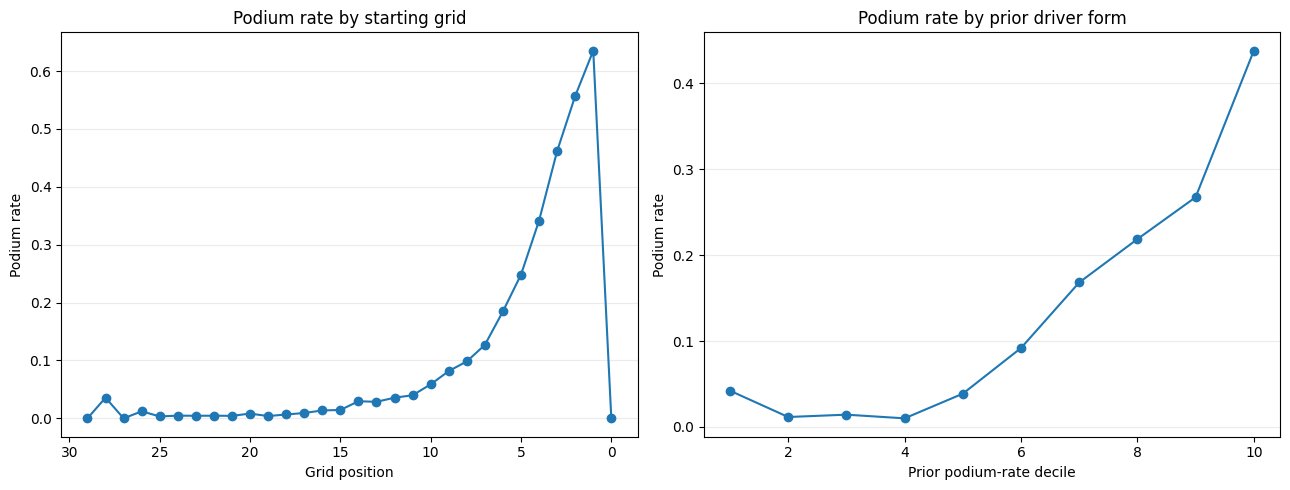

In [139]:
from pathlib import Path

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
grid_rates = modeling_table.dropna(subset=["grid_position"]).groupby("grid_position", observed=True)["podium"].agg(["mean", "count"]).query("count >= 20")
axes[0].plot(grid_rates.index, grid_rates["mean"], marker="o")
axes[0].invert_xaxis()
axes[0].set(title="Podium rate by starting grid", xlabel="Grid position", ylabel="Podium rate")
axes[0].grid(axis="y", alpha=0.25)
form_data = modeling_table.dropna(subset=["driver_prior_podium_rate"]).copy()
if not form_data.empty:
    form_data["prior_form_decile"] = pd.qcut(form_data["driver_prior_podium_rate"].rank(method="first"), 10, labels=False, duplicates="drop")
    form_rates = form_data.groupby("prior_form_decile", observed=True)["podium"].mean()
    axes[1].plot(form_rates.index + 1, form_rates.values, marker="o")
axes[1].set(title="Podium rate by prior driver form", xlabel="Prior podium-rate decile", ylabel="Podium rate")
axes[1].grid(axis="y", alpha=0.25)
fig.tight_layout()
OUTPUT_DIR = Path("/kaggle/working/outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
fig.savefig(OUTPUT_DIR / "feature_justification.png", dpi=160, bbox_inches="tight")
plt.show()

,correlation_with_podium
qualifying_position,-0.486682
grid_position,-0.364069
constructor_prior_standing_position,-0.357247
driver_prior_standing_position,-0.297589
driver_prior_mean_finish,-0.283029
is_home_race,-0.020971
year,0.022031
driver_circuit_prior_starts,0.147352
driver_prior_starts,0.163933
driver_circuit_prior_podium_rate,0.254853


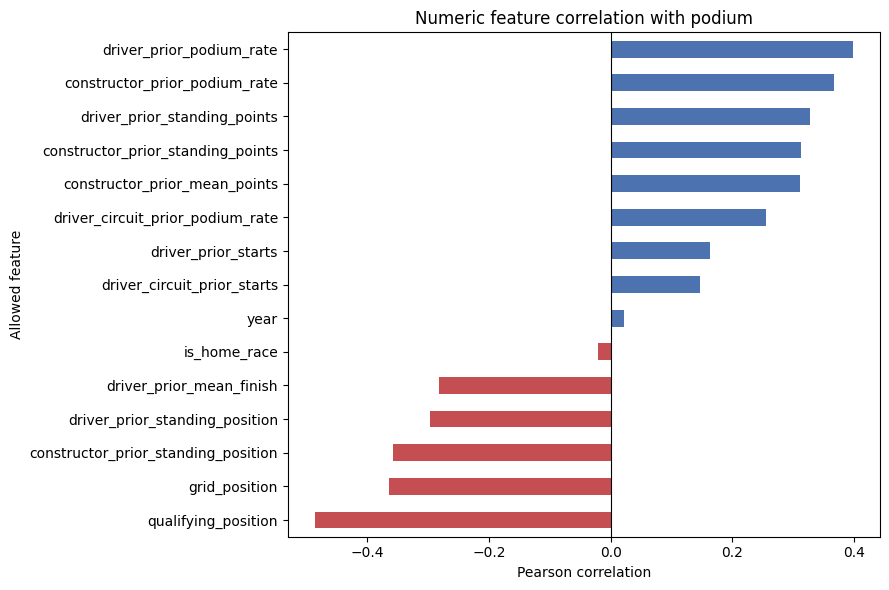

In [140]:
correlation_features = [
    "year", "grid_position", "qualifying_position", "is_home_race",
    "driver_prior_starts", "driver_prior_podium_rate", "driver_prior_mean_finish",
    "constructor_prior_podium_rate", "constructor_prior_mean_points",
    "driver_circuit_prior_starts", "driver_circuit_prior_podium_rate",
    "driver_prior_standing_points", "driver_prior_standing_position",
    "constructor_prior_standing_points", "constructor_prior_standing_position",
]
feature_correlations = modeling_table[correlation_features + ["podium"]].corr(numeric_only=True)["podium"].drop("podium").dropna().sort_values()
display(feature_correlations.rename("correlation_with_podium").to_frame())
fig, ax = plt.subplots(figsize=(9, 6))
feature_correlations.plot(kind="barh", ax=ax, color=["#c44e52" if value < 0 else "#4c72b0" for value in feature_correlations])
ax.axvline(0, color="black", linewidth=0.8)
ax.set(title="Numeric feature correlation with podium", xlabel="Pearson correlation", ylabel="Allowed feature")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "feature_correlations.png", dpi=160, bbox_inches="tight")
plt.show()

# Part 4 — Neural Network, Ablation, XAI & Inference

## Part 4 Overview

### Goal

The aim of this section is to train and evaluate a **shallow neural network** for podium prediction using only information available **after qualifying and before the race starts**, then explain the model using ablation and XAI methods.

### Part 4 Workflow

| Stage | Purpose |
|---|---|
| Data handoff | Reuse Person 2's leakage-safe `modeling_table` |
| Validation | Confirm target, year field, class balance, and row uniqueness |
| Feature selection | Use Person 2's exact 16 allowed predictors |
| Chronological split | Train on past seasons and evaluate on future seasons |
| Preprocessing | Impute missing values, scale numeric features, one-hot encode circuit |
| NN Trial 1 | Baseline shallow architecture |
| NN Trial 2 | Larger shallow architecture with dropout |
| Model selection | Choose using validation PR-AUC |
| Test evaluation | Evaluate the selected model once on unseen test seasons |
| Ablation | Remove feature groups to measure their contribution |
| Permutation importance | Measure validation PR-AUC drop after feature shuffling |
| SHAP | Explain global and local model behavior |
| Inference | Predict on complete and partially missing records |

### Important Evaluation Principle

The **test set is not used to select the architecture, threshold, or hyperparameters**.  
All choices are made using training and validation data only, and the test period is kept for final unseen evaluation.


## 4.1 Data Handoff & Validation

### Reusing Person 2's Modeling Table

Person 2 constructs the final leakage-safe `modeling_table`. Rather than rebuilding the dataset, this section takes a copy of that table so the neural network uses the **same driver-race rows and engineered features** as the rest of the team pipeline.

The modeling table contains **26,668 driver-race observations and 23 columns**.


In [141]:
import os, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    roc_auc_score, average_precision_score, f1_score,
    precision_recall_curve, roc_curve, confusion_matrix,
    classification_report
)

import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input
from tensorflow.keras.callbacks import EarlyStopping

warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)

try:
    import shap
    SHAP_AVAILABLE = True
    print("SHAP:", shap.__version__)
except Exception as e:
    SHAP_AVAILABLE = False
    print("SHAP import failed:", e)

TensorFlow: 2.20.0
SHAP: 0.52.0


In [142]:
df = modeling_table.copy()
DATA_READY = True

print("Loaded modeling table from Person 2")
print("Shape:", df.shape)
display(df.head())

Loaded modeling table from Person 2
Shape: (26668, 23)


,raceId,driverId,constructorId,year,circuitId,race_date,circuit_country,driver_nationality,grid_position,qualifying_position,...,driver_prior_mean_finish,constructor_prior_podium_rate,constructor_prior_mean_points,driver_circuit_prior_starts,driver_circuit_prior_podium_rate,driver_prior_standing_points,driver_prior_standing_position,constructor_prior_standing_points,constructor_prior_standing_position,podium
0,833,579,51,1950,9,1950-05-13,UK,Argentine,3,NaN,...,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,0
1,833,589,105,1950,9,1950-05-13,UK,Monegasque,11,NaN,...,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,0
2,833,619,151,1950,9,1950-05-13,UK,British,13,NaN,...,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,0
3,833,627,154,1950,9,1950-05-13,UK,French,9,NaN,...,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,0
4,833,640,105,1950,9,1950-05-13,UK,Swiss,8,NaN,...,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,0


### Target and Modeling-Grain Checks

Before training, we verify four things:

- target column is `podium`;
- year column is `year`;
- podium target is binary;
- there is exactly one row per `(raceId, driverId)`.

The observed podium prevalence is **12.67%**, confirming a meaningful class imbalance. This is why accuracy alone would be misleading and why PR-AUC is especially important.


In [143]:
target_col = "podium"
year_col = "year"

required = {target_col, year_col}
missing = required - set(df.columns)

if missing:
    raise ValueError(f"Missing required columns: {missing}")

if not df[target_col].dropna().isin([0, 1]).all():
    raise ValueError("podium target must be binary 0/1")

print("Target:", target_col)
print("Year column:", year_col)
print("Podium prevalence:", round(df[target_col].mean(), 4))

if {"raceId", "driverId"}.issubset(df.columns):
    duplicate_pairs = df.duplicated(["raceId", "driverId"]).sum()
    print("Duplicate (raceId, driverId) rows:", duplicate_pairs)

Target: podium
Year column: year
Podium prevalence: 0.1267
Duplicate (raceId, driverId) rows: 0


## 4.2 Final Feature Set

The neural network uses the **exact 16 predictors defined by Person 2**. No additional post-race variables are introduced.

The feature families represented are:

| Feature family | Examples |
|---|---|
| Race context | `year`, `circuitId`, `is_home_race` |
| Starting position | `grid_position`, `qualifying_position` |
| Driver history | prior starts, podium rate, mean finish |
| Constructor history | prior podium rate, mean points |
| Circuit-specific history | driver starts and podium rate at circuit |
| Championship standings | prior driver and constructor standings |

Identifiers such as `raceId`, `driverId`, and `constructorId` are not used as predictors.


In [144]:
PERSON2_ALLOWED_FEATURES = [
    "year",
    "circuitId",
    "grid_position",
    "qualifying_position",
    "is_home_race",
    "driver_prior_starts",
    "driver_prior_podium_rate",
    "driver_prior_mean_finish",
    "constructor_prior_podium_rate",
    "constructor_prior_mean_points",
    "driver_circuit_prior_starts",
    "driver_circuit_prior_podium_rate",
    "driver_prior_standing_points",
    "driver_prior_standing_position",
    "constructor_prior_standing_points",
    "constructor_prior_standing_position",
]

missing_features = [
    c for c in PERSON2_ALLOWED_FEATURES
    if c not in df.columns
]

if missing_features:
    raise ValueError(f"Missing Person 2 features: {missing_features}")

feature_cols = PERSON2_ALLOWED_FEATURES.copy()

print("Number of features:", len(feature_cols))
print(feature_cols)

Number of features: 16
['year', 'circuitId', 'grid_position', 'qualifying_position', 'is_home_race', 'driver_prior_starts', 'driver_prior_podium_rate', 'driver_prior_mean_finish', 'constructor_prior_podium_rate', 'constructor_prior_mean_points', 'driver_circuit_prior_starts', 'driver_circuit_prior_podium_rate', 'driver_prior_standing_points', 'driver_prior_standing_position', 'constructor_prior_standing_points', 'constructor_prior_standing_position']


## 4.3 Chronological Train / Validation / Test Split

A chronological split is used instead of a random split so that the model is always evaluated on **future seasons relative to its training data**.

| Split | Seasons | Rows | Podium rate |
|---|---:|---:|---:|
| Train | 1950–2019 | 24,529 | 12.46% |
| Validation | 2020–2021 | 780 | 15.00% |
| Test | 2022–2024 | 1,359 | 15.01% |

### Why this split?

A random split could place observations from the same racing era on both sides of the split and make performance look more optimistic. The chronological split better reflects the real use case: learning from historical seasons and predicting later ones.


In [145]:
work = df.dropna(subset=[target_col, year_col]).copy()

work[year_col] = pd.to_numeric(
    work[year_col],
    errors="coerce"
)

work = work.dropna(subset=[year_col])

train_df = work[
    work[year_col] <= 2019
].copy()

val_df = work[
    work[year_col].between(2020, 2021)
].copy()

test_df = work[
    work[year_col] >= 2022
].copy()

print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

print(
    "Train years:",
    int(train_df[year_col].min()),
    "-",
    int(train_df[year_col].max())
)

print(
    "Validation years:",
    int(val_df[year_col].min()),
    "-",
    int(val_df[year_col].max())
)

print(
    "Test years:",
    int(test_df[year_col].min()),
    "-",
    int(test_df[year_col].max())
)

Train: (24529, 23)
Validation: (780, 23)
Test: (1359, 23)
Train years: 1950 - 2019
Validation years: 2020 - 2021
Test years: 2022 - 2024


In [146]:
X_train_raw = train_df[feature_cols].copy()
y_train = train_df[target_col].astype(int).to_numpy()

X_val_raw = val_df[feature_cols].copy()
y_val = val_df[target_col].astype(int).to_numpy()

X_test_raw = test_df[feature_cols].copy()
y_test = test_df[target_col].astype(int).to_numpy()

print("Train podium rate:", round(y_train.mean(), 4))
print("Validation podium rate:", round(y_val.mean(), 4))
print("Test podium rate:", round(y_test.mean(), 4))

Train podium rate: 0.1246
Validation podium rate: 0.15
Test podium rate: 0.1501


## 4.4 Preprocessing

The neural network receives a fully numeric matrix.

### Numeric features
Numeric predictors are processed with:

1. **median imputation** for missing values;
2. **missing-value indicator columns** so the model can learn whether missingness itself carries information;
3. **standardization** using `StandardScaler`.

### Categorical feature
`circuitId` is treated as a nominal category rather than a numeric quantity and is encoded using:

- most-frequent imputation;
- one-hot encoding;
- `handle_unknown="ignore"` so unseen categories do not break inference.

### Leakage control
The preprocessing pipeline is fit **only on the training split** and then applied unchanged to validation and test data.

After preprocessing, the original 16 features expand to **96 transformed inputs**.


In [147]:
CATEGORICAL_RAW = ["circuitId"]

def build_preprocessor(X):
    categorical_cols = [
        c for c in CATEGORICAL_RAW
        if c in X.columns
    ]

    numeric_cols = [
        c for c in X.columns
        if c not in categorical_cols
    ]

    num_pipe = Pipeline([
        (
            "imputer",
            SimpleImputer(
                strategy="median",
                add_indicator=True
            )
        ),
        (
            "scaler",
            StandardScaler()
        )
    ])

    cat_pipe = Pipeline([
        (
            "imputer",
            SimpleImputer(
                strategy="most_frequent"
            )
        ),
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            )
        )
    ])

    transformers = [
        ("num", num_pipe, numeric_cols)
    ]

    if categorical_cols:
        transformers.append(
            ("cat", cat_pipe, categorical_cols)
        )

    preprocessor = ColumnTransformer(
        transformers=transformers,
        remainder="drop"
    )

    return (
        preprocessor,
        numeric_cols,
        categorical_cols
    )

In [148]:
for split_x in [
    X_train_raw,
    X_val_raw,
    X_test_raw
]:
    split_x["circuitId"] = (
        split_x["circuitId"]
        .astype("string")
    )

preprocessor, numeric_cols, categorical_cols = (
    build_preprocessor(X_train_raw)
)

X_train = np.asarray(
    preprocessor.fit_transform(X_train_raw),
    dtype=np.float32
)

X_val = np.asarray(
    preprocessor.transform(X_val_raw),
    dtype=np.float32
)

X_test = np.asarray(
    preprocessor.transform(X_test_raw),
    dtype=np.float32
)

print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("X_test:", X_test.shape)

print("Numeric features:", len(numeric_cols))
print("Categorical features:", categorical_cols)

X_train: (24529, 96)
X_val: (780, 96)
X_test: (1359, 96)
Numeric features: 15
Categorical features: ['circuitId']


In [149]:
try:
    transformed_feature_names = (
        preprocessor
        .get_feature_names_out()
        .tolist()
    )
except Exception:
    transformed_feature_names = [
        f"x{i}"
        for i in range(X_train.shape[1])
    ]

print(
    "Number of transformed features:",
    len(transformed_feature_names)
)

print(
    "First 20 transformed features:"
)

print(
    transformed_feature_names[:20]
)

Number of transformed features: 96
First 20 transformed features:
['num__year', 'num__grid_position', 'num__qualifying_position', 'num__is_home_race', 'num__driver_prior_starts', 'num__driver_prior_podium_rate', 'num__driver_prior_mean_finish', 'num__constructor_prior_podium_rate', 'num__constructor_prior_mean_points', 'num__driver_circuit_prior_starts', 'num__driver_circuit_prior_podium_rate', 'num__driver_prior_standing_points', 'num__driver_prior_standing_position', 'num__constructor_prior_standing_points', 'num__constructor_prior_standing_position', 'num__missingindicator_qualifying_position', 'num__missingindicator_driver_prior_podium_rate', 'num__missingindicator_driver_prior_mean_finish', 'num__missingindicator_constructor_prior_podium_rate', 'num__missingindicator_constructor_prior_mean_points']


## 4.5 Evaluation Strategy

Three required metrics are used:

| Metric | Why it matters |
|---|---|
| ROC-AUC | Measures ranking ability across thresholds |
| PR-AUC | Especially useful for the minority podium class |
| F1 | Balances precision and recall at a chosen threshold |

### Threshold selection

The probability threshold is **not fixed automatically at 0.50**.  
Instead, the threshold that maximizes validation F1 is selected using the validation set only.

For model selection, **validation PR-AUC is prioritized** because podium finishes are relatively rare.


In [150]:
def best_f1_threshold(y_true, y_prob):
    precision, recall, thresholds = (
        precision_recall_curve(
            y_true,
            y_prob
        )
    )

    if len(thresholds) == 0:
        return 0.5

    f1_scores = (
        2 * precision[:-1] * recall[:-1]
        /
        np.clip(
            precision[:-1] + recall[:-1],
            1e-12,
            None
        )
    )

    best_index = int(
        np.nanargmax(f1_scores)
    )

    return float(
        thresholds[best_index]
    )


def evaluate_model(
    y_true,
    y_prob,
    threshold
):

    y_pred = (
        np.asarray(y_prob)
        >= threshold
    ).astype(int)

    return {
        "ROC-AUC":
            roc_auc_score(
                y_true,
                y_prob
            ),

        "PR-AUC":
            average_precision_score(
                y_true,
                y_prob
            ),

        "F1":
            f1_score(
                y_true,
                y_pred
            ),

        "Threshold":
            threshold
    }

In [151]:
def plot_roc_pr(
    y_true,
    y_prob,
    title_prefix
):

    # ROC
    fpr, tpr, _ = roc_curve(
        y_true,
        y_prob
    )

    roc_auc = roc_auc_score(
        y_true,
        y_prob
    )

    plt.figure(figsize=(6, 5))

    plt.plot(
        fpr,
        tpr,
        label=f"AUC = {roc_auc:.3f}"
    )

    plt.plot(
        [0, 1],
        [0, 1],
        linestyle="--"
    )

    plt.xlabel(
        "False Positive Rate"
    )

    plt.ylabel(
        "True Positive Rate"
    )

    plt.title(
        f"{title_prefix} — ROC Curve"
    )

    plt.legend()

    plt.show()


    # Precision Recall
    precision, recall, _ = (
        precision_recall_curve(
            y_true,
            y_prob
        )
    )

    pr_auc = (
        average_precision_score(
            y_true,
            y_prob
        )
    )

    plt.figure(figsize=(6, 5))

    plt.plot(
        recall,
        precision,
        label=f"PR-AUC = {pr_auc:.3f}"
    )

    plt.xlabel("Recall")

    plt.ylabel("Precision")

    plt.title(
        f"{title_prefix} — Precision Recall Curve"
    )

    plt.legend()

    plt.show()

## 4.6 Neural Network Trials

Two shallow feed-forward architectures are compared.

### Trial 1 — Baseline

`Input → Dense(32, ReLU) → Dense(16, ReLU) → Sigmoid`

This is a simple two-hidden-layer baseline.

### Trial 2 — Regularized Alternative

`Input → Dense(64, ReLU) → Dropout(0.20) → Dense(32, ReLU) → Sigmoid`

Trial 2 has a slightly larger hidden representation and includes dropout to reduce overfitting.

Both models use:

- Adam optimizer;
- binary cross-entropy loss;
- early stopping on validation loss;
- restoration of the best validation-loss weights.


In [152]:
def build_nn_trial_1(
    input_dim
):

    model = Sequential([
        Input(
            shape=(input_dim,)
        ),

        Dense(
            32,
            activation="relu"
        ),

        Dense(
            16,
            activation="relu"
        ),

        Dense(
            1,
            activation="sigmoid"
        )
    ])

    model.compile(
        optimizer="adam",
        loss="binary_crossentropy"
    )

    return model

In [153]:
def build_nn_trial_2(
    input_dim
):

    model = Sequential([
        Input(
            shape=(input_dim,)
        ),

        Dense(
            64,
            activation="relu"
        ),

        Dropout(
            0.20
        ),

        Dense(
            32,
            activation="relu"
        ),

        Dense(
            1,
            activation="sigmoid"
        )
    ])

    model.compile(
        optimizer="adam",
        loss="binary_crossentropy"
    )

    return model

In [154]:
def train_nn(
    builder,
    X_train,
    y_train,
    X_val,
    y_val,
    verbose=0
):

    tf.keras.backend.clear_session()

    random.seed(SEED)
    np.random.seed(SEED)
    tf.random.set_seed(SEED)

    model = builder(
        X_train.shape[1]
    )

    early_stopping = (
        EarlyStopping(
            monitor="val_loss",
            patience=8,
            min_delta=0.0001,
            restore_best_weights=True
        )
    )

    history = model.fit(
        X_train,
        y_train,

        validation_data=(
            X_val,
            y_val
        ),

        epochs=150,

        batch_size=32,

        callbacks=[
            early_stopping
        ],

        verbose=verbose
    )

    return (
        model,
        history
    )

### Trial 1 Training

The first architecture is trained with early stopping. Its validation probability outputs are later used to choose the best F1 threshold and compute ROC-AUC, PR-AUC, and F1.


In [155]:
model1, history1 = train_nn(
    build_nn_trial_1,

    X_train,
    y_train,

    X_val,
    y_val,

    verbose=1
)

Epoch 1/150
767/767 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - loss: 0.2645 - val_loss: 0.2358
Epoch 2/150
767/767 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.2409 - val_loss: 0.2319
Epoch 3/150
767/767 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.2376 - val_loss: 0.2298
Epoch 4/150
767/767 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.2354 - val_loss: 0.2293
Epoch 5/150
767/767 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.2337 - val_loss: 0.2291
Epoch 6/150
767/767 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.2322 - val_loss: 0.2295
Epoch 7/150
767/767 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.2309 - val_loss: 0.2295
Epoch 8/150
767/767 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.2295 - val_loss: 0.2303
Epoch 9/150
767/767 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.2284 - val_loss: 0.2304
Epoch 10/150
767/767 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.2274 - val_loss: 0.2324
Epoch 11/150
767/767 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.2262 - val_loss: 0.2331
Epoch 12/150
767/767 ━━━━━━━━━━━━━━━━━━━━

In [156]:
def plot_history(
    history,
    title
):

    plt.figure(
        figsize=(7, 5)
    )

    plt.plot(
        history.history["loss"],
        label="Train Loss"
    )

    plt.plot(
        history.history["val_loss"],
        label="Validation Loss"
    )

    plt.xlabel("Epoch")

    plt.ylabel(
        "Binary Cross-Entropy Loss"
    )

    plt.title(title)

    plt.legend()

    plt.show()

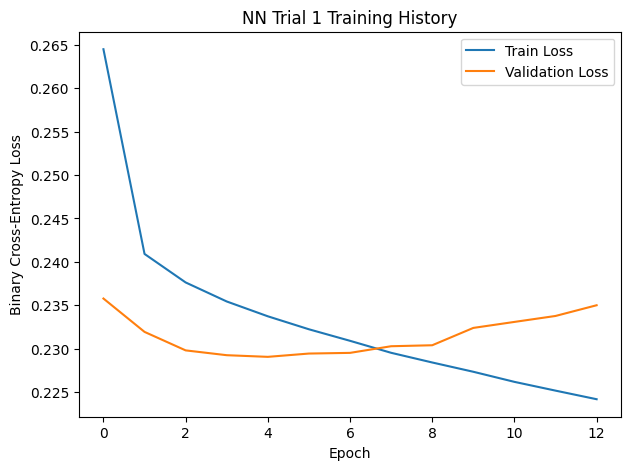

In [157]:
plot_history(
    history1,
    "NN Trial 1 Training History"
)

In [158]:
val_prob_1 = (
    model1
    .predict(
        X_val,
        verbose=0
    )
    .ravel()
)

threshold_1 = (
    best_f1_threshold(
        y_val,
        val_prob_1
    )
)

results_1 = (
    evaluate_model(
        y_val,
        val_prob_1,
        threshold_1
    )
)

print(
    "Trial 1 threshold:",
    threshold_1
)

print(
    results_1
)

Trial 1 threshold: 0.3977929949760437
{'ROC-AUC': np.float64(0.9290714313338748), 'PR-AUC': np.float64(0.69519664559571), 'F1': 0.6929824561403509, 'Threshold': 0.3977929949760437}


#### Trial 1 Result

Trial 1 achieved:

- **Validation ROC-AUC:** 0.9291
- **Validation PR-AUC:** 0.6952
- **Validation F1:** 0.6930
- **Selected threshold:** 0.3978

This establishes the baseline neural-network performance for comparison with Trial 2.


### Trial 2 Training

The second architecture adds more hidden capacity and 20% dropout. The same training, validation, and threshold-selection procedure is used so the comparison remains fair.


In [159]:
model2, history2 = train_nn(
    build_nn_trial_2,

    X_train,
    y_train,

    X_val,
    y_val,

    verbose=1
)

Epoch 1/150
767/767 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 0.2738 - val_loss: 0.2362
Epoch 2/150
767/767 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.2443 - val_loss: 0.2341
Epoch 3/150
767/767 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.2402 - val_loss: 0.2305
Epoch 4/150
767/767 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.2376 - val_loss: 0.2309
Epoch 5/150
767/767 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.2368 - val_loss: 0.2288
Epoch 6/150
767/767 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.2351 - val_loss: 0.2352
Epoch 7/150
767/767 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.2340 - val_loss: 0.2300
Epoch 8/150
767/767 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.2310 - val_loss: 0.2335
Epoch 9/150
767/767 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.2304 - val_loss: 0.2298
Epoch 10/150
767/767 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.2294 - val_loss: 0.2327
Epoch 11/150
767/767 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.2281 - val_loss: 0.2320
Epoch 12/150
767/767 ━━━━━━━━━━━━━━━━━━━━

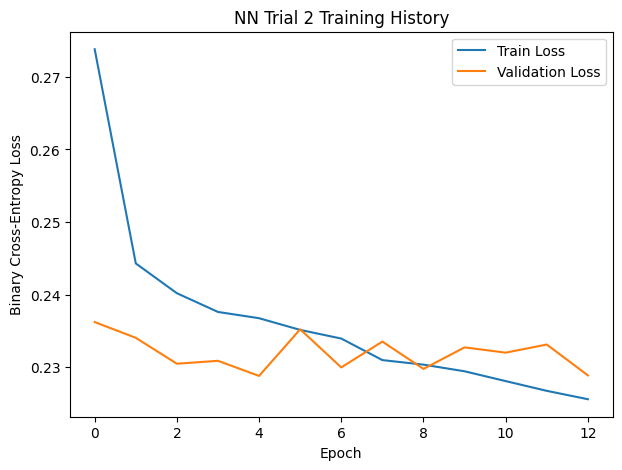

In [160]:
plot_history(
    history2,
    "NN Trial 2 Training History"
)

In [161]:
val_prob_2 = (
    model2
    .predict(
        X_val,
        verbose=0
    )
    .ravel()
)

threshold_2 = (
    best_f1_threshold(
        y_val,
        val_prob_2
    )
)

results_2 = (
    evaluate_model(
        y_val,
        val_prob_2,
        threshold_2
    )
)

print(
    "Trial 2 threshold:",
    threshold_2
)

print(
    results_2
)

Trial 2 threshold: 0.4115222692489624
{'ROC-AUC': np.float64(0.9291874540743319), 'PR-AUC': np.float64(0.7237817503566575), 'F1': 0.6986899563318777, 'Threshold': 0.4115222692489624}


#### Trial 2 Result

Trial 2 achieved:

- **Validation ROC-AUC:** 0.9292
- **Validation PR-AUC:** 0.7238
- **Validation F1:** 0.6987
- **Selected threshold:** 0.4115

Its ROC-AUC is very similar to Trial 1, but its **PR-AUC is substantially higher**, which is important for the imbalanced podium class.


### Model Comparison and Selection

The two networks are compared on the **same validation data**.  
The selected architecture is the one with the stronger validation PR-AUC, with F1 used as a secondary check.

No test-set result is used in this decision.


In [162]:
nn_comparison = pd.DataFrame([
    {
        "Model":
            "NN Trial 1 (32-16)",

        **results_1
    },

    {
        "Model":
            "NN Trial 2 (64-32 + Dropout)",

        **results_2
    }
])

nn_comparison = (
    nn_comparison
    .sort_values(
        by=[
            "PR-AUC",
            "F1"
        ],
        ascending=False
    )
    .reset_index(drop=True)
)

display(
    nn_comparison
)

,Model,ROC-AUC,PR-AUC,F1,Threshold
0,NN Trial 2 (64-32 + Dropout),0.929187,0.723782,0.698690,0.411522
1,NN Trial 1 (32-16),0.929071,0.695197,0.692982,0.397793


### Neural Network Model Selection

Two shallow neural-network architectures were compared using the **validation set**.  
NN Trial 2 (64 → Dropout → 32 → 1) achieved the stronger validation performance, with a **PR-AUC of 0.724** and **F1 of 0.699**, compared with a PR-AUC of 0.695 for Trial 1.

Because podium finishes are the minority class, **PR-AUC was used as the main model-selection metric**. The classification threshold was also selected using validation data only. The chosen model was therefore **NN Trial 2**, with a threshold of approximately **0.412**.


In [163]:
winner = (
    nn_comparison
    .iloc[0]["Model"]
)

if winner.startswith(
    "NN Trial 1"
):

    best_model = model1

    best_threshold = (
        threshold_1
    )

    best_label = (
        "NN Trial 1"
    )

else:

    best_model = model2

    best_threshold = (
        threshold_2
    )

    best_label = (
        "NN Trial 2"
    )


print(
    "Selected model:",
    best_label
)

print(
    "Selected threshold:",
    round(
        best_threshold,
        4
    )
)

Selected model: NN Trial 2
Selected threshold: 0.4115


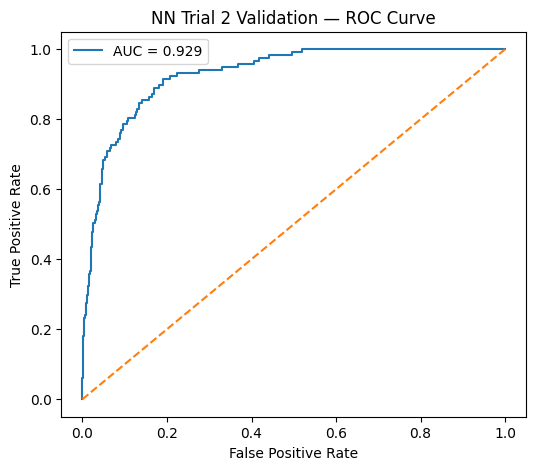

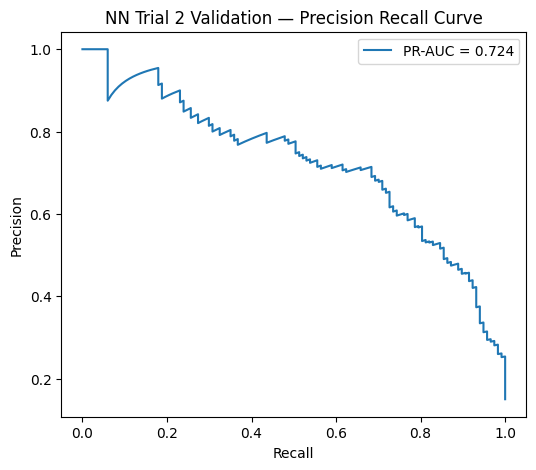

In [164]:
best_val_prob = (
    best_model
    .predict(
        X_val,
        verbose=0
    )
    .ravel()
)

plot_roc_pr(
    y_val,
    best_val_prob,
    f"{best_label} Validation"
)

## 4.7 Final Unseen Test Evaluation

After selecting NN Trial 2 and fixing its validation-derived threshold, the chosen model is evaluated on:

- training data;
- validation data;
- the fully unseen 2022–2024 test period.

This gives a direct view of generalization across time.


In [165]:
split_results = []

for (
    split_name,
    X_split,
    y_split
) in [

    (
        "Train",
        X_train,
        y_train
    ),

    (
        "Validation",
        X_val,
        y_val
    ),

    (
        "Test",
        X_test,
        y_test
    )
]:

    probabilities = (
        best_model
        .predict(
            X_split,
            verbose=0
        )
        .ravel()
    )

    metrics = (
        evaluate_model(
            y_split,
            probabilities,
            best_threshold
        )
    )

    split_results.append({
        "Split":
            split_name,

        **metrics
    })


final_nn_results = (
    pd.DataFrame(
        split_results
    )
)

display(
    final_nn_results
)

,Split,ROC-AUC,PR-AUC,F1,Threshold
0,Train,0.911336,0.593236,0.567707,0.411522
1,Validation,0.929187,0.723782,0.698690,0.411522
2,Test,0.927723,0.670061,0.618557,0.411522


### Final Performance Summary

| Split | ROC-AUC | PR-AUC | F1 | Threshold |
|---|---:|---:|---:|---:|
| Train | 0.9113 | 0.5932 | 0.5677 | 0.4115 |
| Validation | 0.9292 | 0.7238 | 0.6987 | 0.4115 |
| Test | 0.9277 | 0.6701 | 0.6186 | 0.4115 |

The selected model maintains a high **test ROC-AUC of 0.928** and a **test PR-AUC of 0.670**, showing strong ranking ability on future seasons.

The lower test PR-AUC compared with validation indicates some performance reduction on unseen seasons, which is expected in a temporal evaluation.


### Train, Validation, and Test Performance

The selected neural network generalized well to unseen seasons. It achieved a **test ROC-AUC of 0.928**, **test PR-AUC of 0.670**, and **test F1 of 0.619**.

The validation PR-AUC was higher than the training PR-AUC. This does not by itself indicate leakage, because the splits correspond to different Formula 1 eras and may differ in difficulty and class structure. The important point is that the completely unseen test set still retained strong discrimination.

All hyperparameter and threshold decisions were made using the training and validation sets only; the test set was reserved for final evaluation.


In [166]:
split_results = []

for (
    split_name,
    X_split,
    y_split
) in [

    (
        "Train",
        X_train,
        y_train
    ),

    (
        "Validation",
        X_val,
        y_val
    ),

    (
        "Test",
        X_test,
        y_test
    )
]:

    probabilities = (
        best_model
        .predict(
            X_split,
            verbose=0
        )
        .ravel()
    )

    metrics = (
        evaluate_model(
            y_split,
            probabilities,
            best_threshold
        )
    )

    split_results.append({
        "Split":
            split_name,

        **metrics
    })


final_nn_results = (
    pd.DataFrame(
        split_results
    )
)

display(
    final_nn_results
)

,Split,ROC-AUC,PR-AUC,F1,Threshold
0,Train,0.911336,0.593236,0.567707,0.411522
1,Validation,0.929187,0.723782,0.698690,0.411522
2,Test,0.927723,0.670061,0.618557,0.411522


In [167]:
test_prob = (
    best_model
    .predict(
        X_test,
        verbose=0
    )
    .ravel()
)

test_pred = (
    test_prob
    >= best_threshold
).astype(int)


print(
    classification_report(
        y_test,
        test_pred,
        digits=4
    )
)

              precision    recall  f1-score   support

           0     0.9285    0.9446    0.9365      1155
           1     0.6522    0.5882    0.6186       204

    accuracy                         0.8911      1359
   macro avg     0.7903    0.7664    0.7775      1359
weighted avg     0.8870    0.8911    0.8888      1359



In [168]:
cm = confusion_matrix(
    y_test,
    test_pred
)

cm_df = pd.DataFrame(
    cm,

    index=[
        "Actual Non-Podium",
        "Actual Podium"
    ],

    columns=[
        "Predicted Non-Podium",
        "Predicted Podium"
    ]
)

display(
    cm_df
)

,Predicted Non-Podium,Predicted Podium
Actual Non-Podium,1091,64
Actual Podium,84,120


### Test Classification Behavior

At the selected threshold, the model correctly predicts **120 podium finishes** while missing **84** podium cases.

For the podium class:

- **Precision:** 0.6522
- **Recall:** 0.5882
- **F1:** 0.6186

This means that when the model predicts a podium, roughly two thirds of those predictions are correct, while it identifies a little under 60% of all true podiums.


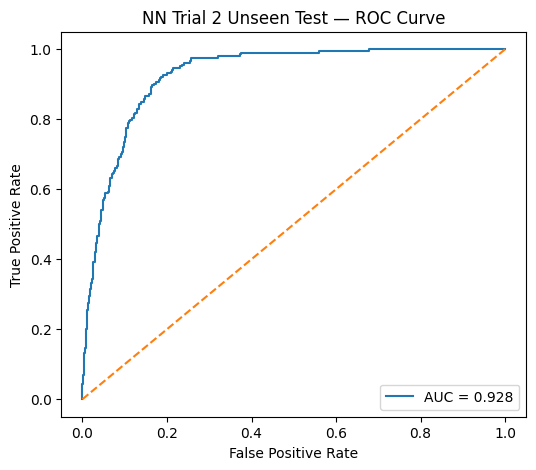

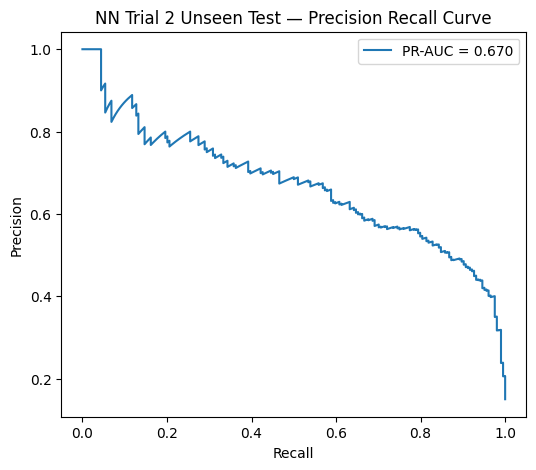

In [169]:
plot_roc_pr(
    y_test,
    test_prob,
    f"{best_label} Unseen Test"
)

## 4.8 Feature-Group Ablation

Ablation measures how much each **group of raw features** contributes to validation performance.

The full model is retrained repeatedly, each time removing one feature group:

| Group | Removed variables |
|---|---|
| Grid | starting grid position |
| Qualifying | qualifying position |
| Driver form | driver historical performance features |
| Constructor form | constructor historical performance features |
| Standings | driver and constructor championship standings |
| Context | year, circuit, home-race indicator |

A drop in PR-AUC after removing a group suggests that the group contributes useful predictive information.


In [170]:
feature_groups = {

    "grid": [
        "grid_position"
    ],

    "qualifying": [
        "qualifying_position"
    ],

    "driver_form": [
        "driver_prior_starts",
        "driver_prior_podium_rate",
        "driver_prior_mean_finish",
        "driver_circuit_prior_starts",
        "driver_circuit_prior_podium_rate"
    ],

    "constructor_form": [
        "constructor_prior_podium_rate",
        "constructor_prior_mean_points"
    ],

    "standings": [
        "driver_prior_standing_points",
        "driver_prior_standing_position",
        "constructor_prior_standing_points",
        "constructor_prior_standing_position"
    ],

    "context": [
        "year",
        "circuitId",
        "is_home_race"
    ]
}


for group_name, cols in (
    feature_groups.items()
):

    print(
        group_name,
        "->",
        cols
    )

grid -> ['grid_position']
qualifying -> ['qualifying_position']
driver_form -> ['driver_prior_starts', 'driver_prior_podium_rate', 'driver_prior_mean_finish', 'driver_circuit_prior_starts', 'driver_circuit_prior_podium_rate']
constructor_form -> ['constructor_prior_podium_rate', 'constructor_prior_mean_points']
standings -> ['driver_prior_standing_points', 'driver_prior_standing_position', 'constructor_prior_standing_points', 'constructor_prior_standing_position']
context -> ['year', 'circuitId', 'is_home_race']


In [171]:
selected_builder = (
    build_nn_trial_1
    if best_label == "NN Trial 1"
    else build_nn_trial_2
)


def run_ablation(
    raw_train,
    y_train,
    raw_val,
    y_val,
    base_features,
    feature_groups
):

    rows = []


    def fit_and_score(
        selected_features,
        experiment_name
    ):

        train_part = (
            raw_train[
                selected_features
            ].copy()
        )

        val_part = (
            raw_val[
                selected_features
            ].copy()
        )


        if "circuitId" in train_part.columns:

            train_part[
                "circuitId"
            ] = (
                train_part[
                    "circuitId"
                ].astype("string")
            )

            val_part[
                "circuitId"
            ] = (
                val_part[
                    "circuitId"
                ].astype("string")
            )


        prep, _, _ = (
            build_preprocessor(
                train_part
            )
        )


        Xt = np.asarray(
            prep.fit_transform(
                train_part
            ),
            dtype=np.float32
        )


        Xv = np.asarray(
            prep.transform(
                val_part
            ),
            dtype=np.float32
        )


        model, _ = train_nn(
            selected_builder,
            Xt,
            y_train,
            Xv,
            y_val,
            verbose=0
        )


        prob = (
            model
            .predict(
                Xv,
                verbose=0
            )
            .ravel()
        )


        threshold = (
            best_f1_threshold(
                y_val,
                prob
            )
        )


        metrics = (
            evaluate_model(
                y_val,
                prob,
                threshold
            )
        )


        rows.append({
            "Experiment":
                experiment_name,

            "Raw Feature Count":
                len(
                    selected_features
                ),

            **metrics
        })


        return metrics


    full_metrics = fit_and_score(
        base_features,
        "Full Feature Set"
    )


    for (
        group_name,
        group_columns
    ) in feature_groups.items():

        remaining = [
            feature
            for feature in base_features
            if feature
            not in group_columns
        ]


        fit_and_score(
            remaining,
            f"Without {group_name}"
        )


    results = pd.DataFrame(
        rows
    )


    results[
        "Δ PR-AUC vs Full"
    ] = (
        results["PR-AUC"]
        -
        full_metrics["PR-AUC"]
    )


    results[
        "Δ ROC-AUC vs Full"
    ] = (
        results["ROC-AUC"]
        -
        full_metrics["ROC-AUC"]
    )


    results[
        "Δ F1 vs Full"
    ] = (
        results["F1"]
        -
        full_metrics["F1"]
    )


    return results

In [172]:
ablation_results = (
    run_ablation(
        X_train_raw,
        y_train,

        X_val_raw,
        y_val,

        feature_cols,
        feature_groups
    )
)

display(
    ablation_results
)

,Experiment,Raw Feature Count,ROC-AUC,PR-AUC,F1,Threshold,Δ PR-AUC vs Full,Δ ROC-AUC vs Full,Δ F1 vs Full
0,Full Feature Set,16,0.929187,0.723782,0.698690,0.411522,0.000000,0.000000,0.000000
1,Without grid,15,0.932617,0.711025,0.709957,0.348273,-0.012757,0.003429,0.011267
2,Without qualifying,15,0.921517,0.709463,0.684211,0.238839,-0.014318,-0.007670,-0.014479
3,Without driver_form,11,0.929536,0.735154,0.701299,0.326340,0.011372,0.000348,0.002609
4,Without constructor_form,14,0.927705,0.713556,0.693227,0.255630,-0.010226,-0.001483,-0.005463
5,Without standings,12,0.929445,0.718050,0.705455,0.180409,-0.005732,0.000258,0.006765
6,Without context,13,0.930322,0.732859,0.708520,0.482227,0.009077,0.001134,0.009830


In [173]:
display(
    ablation_results
    .sort_values(
        "PR-AUC",
        ascending=False
    )
)

,Experiment,Raw Feature Count,ROC-AUC,PR-AUC,F1,Threshold,Δ PR-AUC vs Full,Δ ROC-AUC vs Full,Δ F1 vs Full
3,Without driver_form,11,0.929536,0.735154,0.701299,0.326340,0.011372,0.000348,0.002609
6,Without context,13,0.930322,0.732859,0.708520,0.482227,0.009077,0.001134,0.009830
0,Full Feature Set,16,0.929187,0.723782,0.698690,0.411522,0.000000,0.000000,0.000000
5,Without standings,12,0.929445,0.718050,0.705455,0.180409,-0.005732,0.000258,0.006765
4,Without constructor_form,14,0.927705,0.713556,0.693227,0.255630,-0.010226,-0.001483,-0.005463
1,Without grid,15,0.932617,0.711025,0.709957,0.348273,-0.012757,0.003429,0.011267
2,Without qualifying,15,0.921517,0.709463,0.684211,0.238839,-0.014318,-0.007670,-0.014479


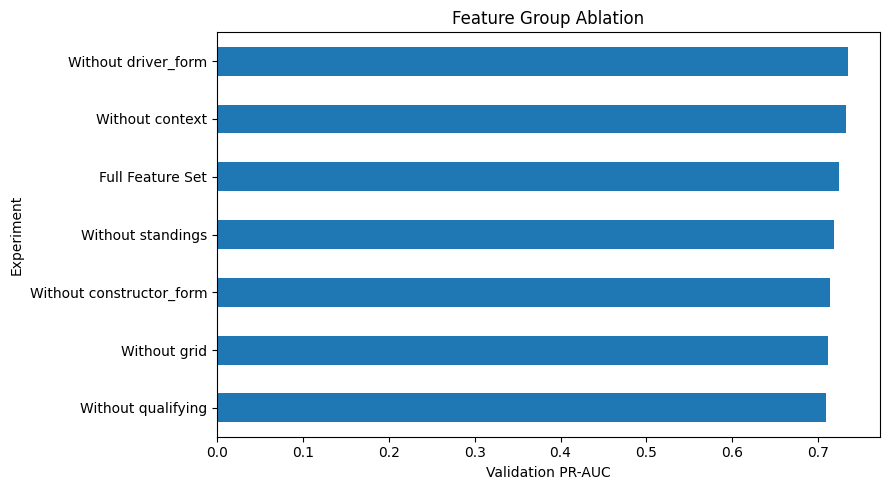

In [174]:
ablation_plot = (
    ablation_results
    .set_index(
        "Experiment"
    )["PR-AUC"]
    .sort_values()
)

plt.figure(
    figsize=(9, 5)
)

ablation_plot.plot(
    kind="barh"
)

plt.xlabel(
    "Validation PR-AUC"
)

plt.title(
    "Feature Group Ablation"
)

plt.tight_layout()

plt.show()

### Ablation Findings

The full model achieved **0.7238 validation PR-AUC**.

The largest harmful removals were:

- **Without qualifying:** PR-AUC fell to 0.7095
- **Without grid:** PR-AUC fell to 0.7110
- **Without constructor form:** PR-AUC fell to 0.7136

This supports the importance of pre-race starting and qualifying information.

Two removals slightly improved validation PR-AUC:

- without driver form: 0.7352
- without context: 0.7329

These small improvements suggest that some variables in those groups may be redundant or noisy when used together with the remaining predictors. They should not be interpreted as universally useless features.


### Ablation Interpretation

The full model achieved a validation **PR-AUC of 0.724**. Removing **qualifying** produced the largest decrease in PR-AUC, to approximately **0.709**, while removing **grid position** reduced PR-AUC to approximately **0.711**. Removing constructor-form features also reduced performance.

Interestingly, removing the **driver-form** group or the broader **context** group slightly improved validation PR-AUC. This suggests that some variables in these groups may be redundant or add noise when combined with the other predictors. This does not mean that these features are universally uninformative; it only reflects their contribution within this specific model and validation period.


## 4.9 Permutation Importance

Permutation importance measures model reliance one transformed feature at a time.

### Method

1. Compute baseline validation PR-AUC.
2. Shuffle one feature column.
3. Recompute PR-AUC.
4. Measure the drop.
5. Repeat several times and average the decrease.

A larger PR-AUC drop means the model depended more strongly on that feature.

Because preprocessing creates one-hot columns and missingness indicators, permutation importance is reported at the **transformed-feature level**.


In [175]:
def permutation_importance_pr_auc(
    model,
    X,
    y,
    feature_names,
    repeats=3
):

    rng = np.random.default_rng(
        SEED
    )

    baseline_probability = (
        model
        .predict(
            X,
            verbose=0
        )
        .ravel()
    )

    baseline_score = (
        average_precision_score(
            y,
            baseline_probability
        )
    )

    rows = []


    for column_index, feature_name in (
        enumerate(feature_names)
    ):

        score_drops = []


        for _ in range(repeats):

            X_permuted = (
                X.copy()
            )

            rng.shuffle(
                X_permuted[
                    :,
                    column_index
                ]
            )

            perm_probability = (
                model
                .predict(
                    X_permuted,
                    verbose=0
                )
                .ravel()
            )

            perm_score = (
                average_precision_score(
                    y,
                    perm_probability
                )
            )

            score_drops.append(
                baseline_score
                -
                perm_score
            )


        rows.append({
            "Feature":
                feature_name,

            "Importance_PR_AUC_Drop":
                float(
                    np.mean(
                        score_drops
                    )
                ),

            "Std":
                float(
                    np.std(
                        score_drops
                    )
                )
        })


    return (
        pd.DataFrame(
            rows
        )
        .sort_values(
            "Importance_PR_AUC_Drop",
            ascending=False
        )
        .reset_index(drop=True)
    )

In [176]:
permutation_df = (
    permutation_importance_pr_auc(
        best_model,

        X_val,
        y_val,

        transformed_feature_names,

        repeats=3
    )
)

display(
    permutation_df.head(20)
)

,Feature,Importance_PR_AUC_Drop,Std
0,num__grid_position,0.107741,0.031538
1,num__qualifying_position,0.071493,0.006586
2,num__driver_prior_podium_rate,0.057017,0.020945
3,num__driver_prior_standing_points,0.034227,0.020543
4,num__constructor_prior_podium_rate,0.022136,0.010630
5,num__missingindicator_driver_prior_podium_rate,0.019242,0.002438
6,num__constructor_prior_standing_points,0.014414,0.007867
7,num__missingindicator_driver_circuit_prior_pod...,0.013327,0.011863
8,num__constructor_prior_standing_position,0.011142,0.004717
9,num__driver_prior_starts,0.009954,0.002560


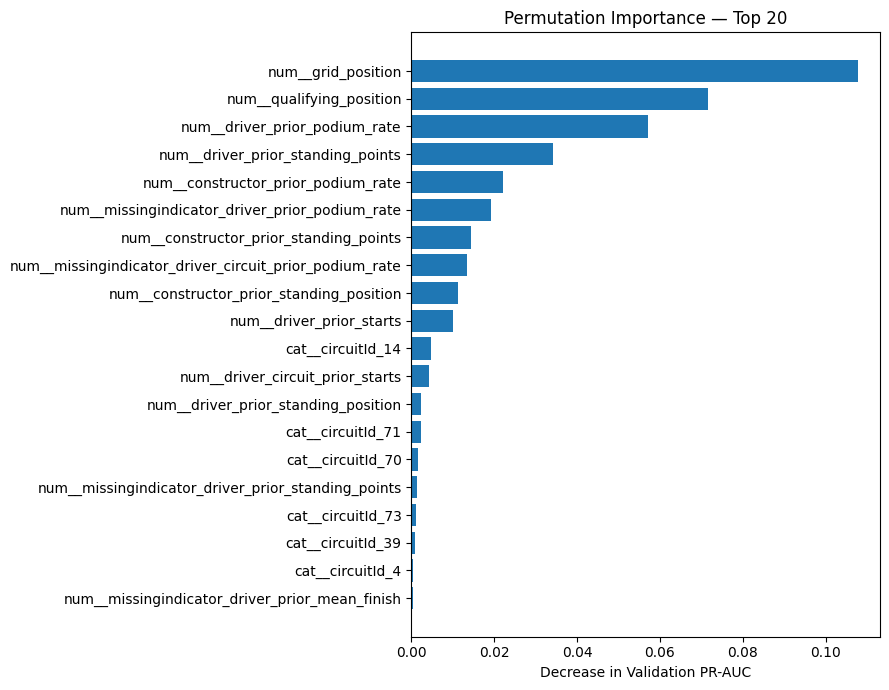

In [177]:
top_permutation = (
    permutation_df
    .head(20)
    .sort_values(
        "Importance_PR_AUC_Drop"
    )
)

plt.figure(
    figsize=(9, 7)
)

plt.barh(
    top_permutation["Feature"],
    top_permutation[
        "Importance_PR_AUC_Drop"
    ]
)

plt.xlabel(
    "Decrease in Validation PR-AUC"
)

plt.title(
    "Permutation Importance — Top 20"
)

plt.tight_layout()

plt.show()

### Permutation-Importance Findings

The strongest predictors were:

| Rank | Feature | Mean PR-AUC drop |
|---:|---|---:|
| 1 | Grid position | 0.1077 |
| 2 | Qualifying position | 0.0715 |
| 3 | Driver prior podium rate | 0.0570 |
| 4 | Driver prior standing points | 0.0342 |
| 5 | Constructor prior podium rate | 0.0221 |

The importance ranking agrees with the ablation experiment: **grid position and qualifying position are central to the model's predictions**.

These values describe predictive reliance, not causal impact.


### Permutation Importance Interpretation

Permutation importance shows how much validation PR-AUC decreases when a feature is randomly shuffled.

The most influential transformed features were:

1. **Grid position**
2. **Qualifying position**
3. **Driver prior podium rate**
4. **Driver prior standing points**
5. **Constructor prior podium rate**

Grid position caused the largest drop in PR-AUC when permuted, which indicates that the neural network relies heavily on starting position information. Qualifying performance and historical driver/constructor strength were also important.

These importance values describe **model reliance**, not causal effects.


## 4.10 SHAP Explainability

SHAP is used in two ways:

### Global explanation
A SHAP summary plot shows which transformed features have the largest overall impact across a sample of validation observations.

### Local explanation
A SHAP waterfall plot explains one specific prediction by showing which features push its probability upward or downward.

To keep runtime practical, SHAP uses:

- 30 training observations as the background sample;
- 25 validation observations for explanation.

The explanation sample is used only for interpretation, not model tuning.


In [178]:
print(
    "SHAP available:",
    SHAP_AVAILABLE
)

SHAP available: True


In [179]:
if SHAP_AVAILABLE:

    rng = np.random.default_rng(
        SEED
    )

    background_size = min(
        30,
        len(X_train)
    )

    explanation_size = min(
        25,
        len(X_val)
    )


    background_indices = (
        rng.choice(
            len(X_train),
            size=background_size,
            replace=False
        )
    )


    explanation_indices = (
        rng.choice(
            len(X_val),
            size=explanation_size,
            replace=False
        )
    )


    X_background = (
        X_train[
            background_indices
        ]
    )


    X_explain = (
        X_val[
            explanation_indices
        ]
    )


    print(
        "Background shape:",
        X_background.shape
    )

    print(
        "Explanation shape:",
        X_explain.shape
    )

Background shape: (30, 96)
Explanation shape: (25, 96)


In [180]:
if SHAP_AVAILABLE:

    def shap_predict(
        x
    ):

        x = np.asarray(
            x,
            dtype=np.float32
        )

        return (
            best_model
            .predict(
                x,
                verbose=0
            )
            .ravel()
        )


    shap_explainer = (
        shap.KernelExplainer(
            shap_predict,
            X_background
        )
    )

In [181]:
if SHAP_AVAILABLE:

    shap_values = (
        shap_explainer
        .shap_values(
            X_explain,
            nsamples=100
        )
    )


    if isinstance(
        shap_values,
        list
    ):

        shap_values = (
            shap_values[0]
        )


    shap_values = np.asarray(
        shap_values
    )


    print(
        "SHAP values shape:",
        shap_values.shape
    )

  0%|          | 0/25 [00:00<?, ?it/s]

SHAP values shape: (25, 96)


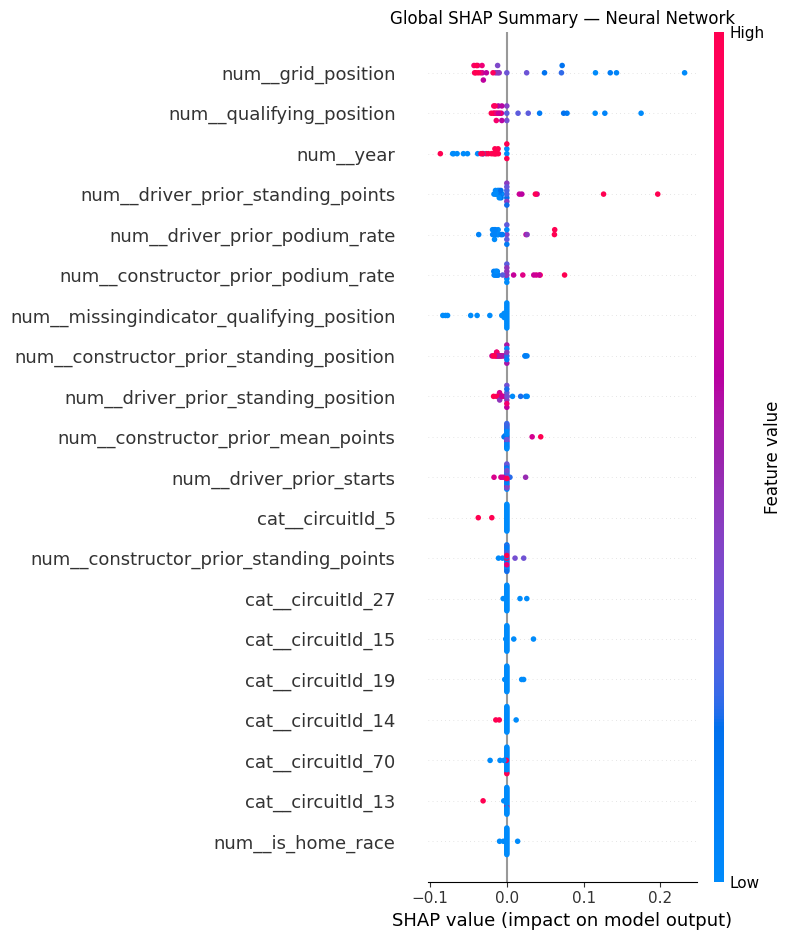

In [182]:
if SHAP_AVAILABLE:

    X_explain_df = (
        pd.DataFrame(
            X_explain,
            columns=
                transformed_feature_names
        )
    )


    shap.summary_plot(
        shap_values,

        X_explain_df,

        max_display=20,

        show=False
    )


    plt.title(
        "Global SHAP Summary — Neural Network"
    )

    plt.tight_layout()

    plt.show()

### Global SHAP Findings

The global SHAP ranking broadly agrees with permutation importance.

The largest overall effects come from:

- grid position;
- qualifying position;
- year;
- driver prior standing points;
- driver prior podium rate;
- constructor prior podium rate.

The consistency across SHAP, permutation importance, and ablation gives greater confidence that the model genuinely relies on pre-race position and historical competitive strength.

SHAP values explain the model's prediction mechanism; they do **not** establish causal relationships.


### Global SHAP Interpretation

The global SHAP summary supports the permutation-importance results. **Grid position** and **qualifying position** had the strongest overall impact on the neural network's predictions, followed by features such as year, prior driver standing points, prior driver podium rate, and prior constructor podium rate.

The spread of SHAP values shows that the same feature can increase or decrease the predicted podium probability depending on its value and the other features present in the observation.

SHAP explanations are used here to explain the model's behavior; they should not be interpreted as evidence of causality.


Predicted podium probability: 0.0065


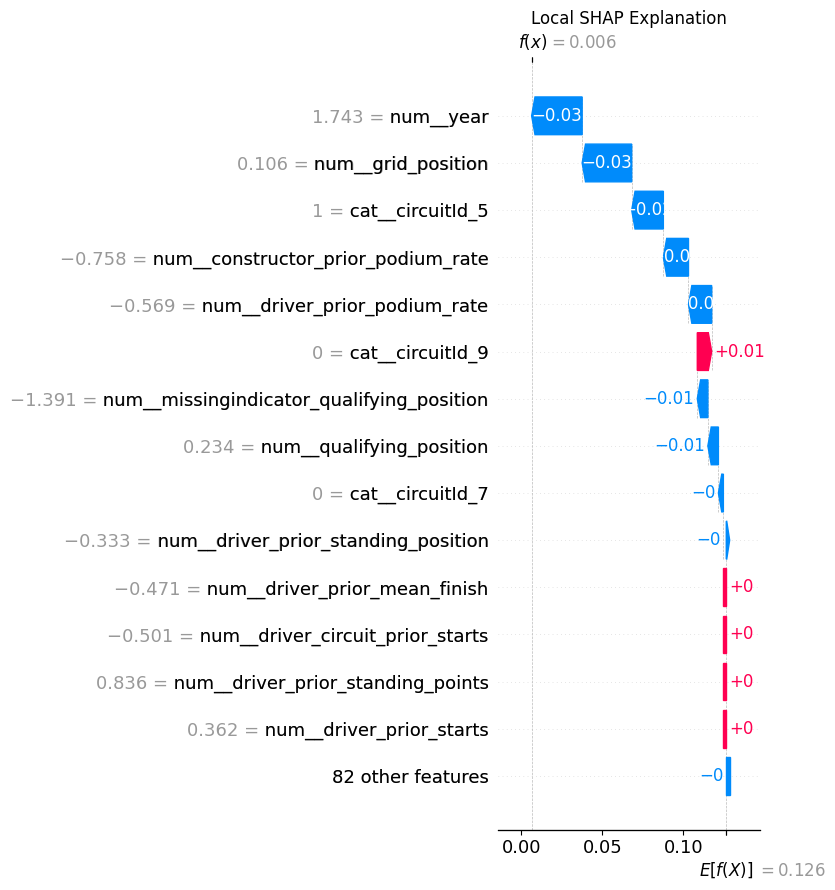

In [183]:
if SHAP_AVAILABLE:

    local_index = 0

    local_values = (
        shap_values[
            local_index
        ]
    )

    local_input = (
        X_explain[
            local_index
        ]
    )


    expected_value = (
        np.asarray(
            shap_explainer
            .expected_value
        )
        .reshape(-1)[0]
    )


    local_explanation = (
        shap.Explanation(
            values=
                local_values,

            base_values=
                expected_value,

            data=
                local_input,

            feature_names=
                transformed_feature_names
        )
    )


    local_probability = float(
        best_model
        .predict(
            local_input
            .reshape(1, -1),

            verbose=0
        )
        .ravel()[0]
    )


    print(
        "Predicted podium probability:",
        round(
            local_probability,
            4
        )
    )


    shap.plots.waterfall(
        local_explanation,

        max_display=15,

        show=False
    )


    plt.title(
        "Local SHAP Explanation"
    )

    plt.tight_layout()

    plt.show()

### Local SHAP Findings

For the selected validation observation, the network predicted a podium probability of only **0.0065**.

The largest downward contributions came from transformed:

- year;
- grid position;
- constructor prior podium rate;
- driver prior podium rate;
- qualifying-related information.

A circuit indicator contributed a small upward effect.

This explanation is specific to one driver-race observation and should not be generalized to every race.


### Local SHAP Interpretation

For the selected validation example, the model predicted a podium probability of approximately **0.0065**, indicating a very low podium likelihood.

The local SHAP explanation shows that transformed **year** and **grid-position** information were among the strongest downward contributions for this case. Other historical driver and constructor variables also contributed to the low prediction, while a circuit indicator provided a small upward contribution.

This explanation is specific to this one driver-race record and should not be generalized to all races.


## 4.11 Inference Function

The final inference function accepts a raw pre-race record, applies the **same fitted preprocessing pipeline**, and returns:

- podium probability;
- binary prediction;
- selected classification threshold.

The function also adds absent feature columns as missing values, allowing the trained imputers to handle partially incomplete input.


In [184]:
def predict_podium(
    record
):

    if isinstance(
        record,
        dict
    ):

        row = pd.DataFrame(
            [record]
        )

    elif isinstance(
        record,
        pd.Series
    ):

        row = (
            record
            .to_frame()
            .T
        )

    elif isinstance(
        record,
        pd.DataFrame
    ):

        row = (
            record.copy()
        )

    else:

        raise TypeError(
            "record must be dict, Series or DataFrame"
        )


    for feature in feature_cols:

        if feature not in row.columns:

            row[
                feature
            ] = np.nan


    row = row[
        feature_cols
    ].copy()


    row[
        "circuitId"
    ] = (
        row[
            "circuitId"
        ].astype("string")
    )


    X_new = np.asarray(
        preprocessor
        .transform(
            row
        ),

        dtype=np.float32
    )


    probability = float(
        best_model
        .predict(
            X_new,
            verbose=0
        )
        .ravel()[0]
    )


    prediction = int(
        probability
        >= best_threshold
    )


    return {
        "podium_probability":
            probability,

        "podium_prediction":
            prediction,

        "threshold":
            float(
                best_threshold
            )
    }

In [185]:
complete_record = (
    X_test_raw
    .iloc[0]
    .copy()
)

complete_prediction = (
    predict_podium(
        complete_record
    )
)

print(
    "Complete Record"
)

print(
    complete_prediction
)

Complete Record
{'podium_probability': 0.7228468656539917, 'podium_prediction': 1, 'threshold': 0.4115222692489624}


In [186]:
partially_missing_record = (
    complete_record.copy()
)

missing_demo_features = [
    "qualifying_position",
    "driver_prior_podium_rate",
    "constructor_prior_standing_position"
]

for feature in (
    missing_demo_features
):

    partially_missing_record[
        feature
    ] = np.nan


missing_prediction = (
    predict_podium(
        partially_missing_record
    )
)


print(
    "Partially Missing Record"
)

print(
    "Missing:",
    missing_demo_features
)

print(
    missing_prediction
)

Partially Missing Record
Missing: ['qualifying_position', 'driver_prior_podium_rate', 'constructor_prior_standing_position']
{'podium_probability': 0.6604197025299072, 'podium_prediction': 1, 'threshold': 0.4115222692489624}


### Inference Demonstration

Two required inference cases are demonstrated.

| Input case | Podium probability | Prediction |
|---|---:|---:|
| Complete record | 0.7228 | 1 |
| Partially missing record | 0.6604 | 1 |

For the partially missing case, the following inputs were deliberately removed:

- `qualifying_position`
- `driver_prior_podium_rate`
- `constructor_prior_standing_position`

The pipeline still produces a valid prediction because missing values are handled by the preprocessing stage.


### Inference Demonstration

The inference function was successfully tested on both required cases.

- With a **complete record**, the model returned a podium probability of approximately **0.723** and predicted podium (`1`).
- With a **partially missing record**, where qualifying position, driver prior podium rate, and constructor prior standing position were removed, the preprocessing pipeline handled the missing values and returned a podium probability of approximately **0.660**, again predicting podium (`1`).

This demonstrates that the final prediction pipeline can accept both complete and partially incomplete pre-race records.


## 4.12 Part 4 Conclusion

The final summary below collects the selected neural network, the common threshold, split-level performance, ablation results, and top permutation features in one place.


In [187]:
print(
    "FINAL PERSON 4 SUMMARY"
)

print(
    "----------------------"
)

print(
    "Best neural network:",
    best_label
)

print(
    "Threshold:",
    round(
        best_threshold,
        4
    )
)

print(
    "\\nTrain / Validation / Test:"
)

display(
    final_nn_results
)

print(
    "\\nAblation results:"
)

display(
    ablation_results
)

print(
    "\\nTop 10 permutation features:"
)

display(
    permutation_df
    .head(10)
)

FINAL PERSON 4 SUMMARY
----------------------
Best neural network: NN Trial 2
Threshold: 0.4115
\nTrain / Validation / Test:


,Split,ROC-AUC,PR-AUC,F1,Threshold
0,Train,0.911336,0.593236,0.567707,0.411522
1,Validation,0.929187,0.723782,0.698690,0.411522
2,Test,0.927723,0.670061,0.618557,0.411522


\nAblation results:


,Experiment,Raw Feature Count,ROC-AUC,PR-AUC,F1,Threshold,Δ PR-AUC vs Full,Δ ROC-AUC vs Full,Δ F1 vs Full
0,Full Feature Set,16,0.929187,0.723782,0.698690,0.411522,0.000000,0.000000,0.000000
1,Without grid,15,0.932617,0.711025,0.709957,0.348273,-0.012757,0.003429,0.011267
2,Without qualifying,15,0.921517,0.709463,0.684211,0.238839,-0.014318,-0.007670,-0.014479
3,Without driver_form,11,0.929536,0.735154,0.701299,0.326340,0.011372,0.000348,0.002609
4,Without constructor_form,14,0.927705,0.713556,0.693227,0.255630,-0.010226,-0.001483,-0.005463
5,Without standings,12,0.929445,0.718050,0.705455,0.180409,-0.005732,0.000258,0.006765
6,Without context,13,0.930322,0.732859,0.708520,0.482227,0.009077,0.001134,0.009830


\nTop 10 permutation features:


,Feature,Importance_PR_AUC_Drop,Std
0,num__grid_position,0.107741,0.031538
1,num__qualifying_position,0.071493,0.006586
2,num__driver_prior_podium_rate,0.057017,0.020945
3,num__driver_prior_standing_points,0.034227,0.020543
4,num__constructor_prior_podium_rate,0.022136,0.010630
5,num__missingindicator_driver_prior_podium_rate,0.019242,0.002438
6,num__constructor_prior_standing_points,0.014414,0.007867
7,num__missingindicator_driver_circuit_prior_pod...,0.013327,0.011863
8,num__constructor_prior_standing_position,0.011142,0.004717
9,num__driver_prior_starts,0.009954,0.002560


### Person 4 Conclusion

The neural-network experiments produced a strong final model, with **ROC-AUC 0.928**, **PR-AUC 0.670**, and **F1 0.619** on the unseen test period.

Across the explanation methods, **grid position and qualifying position were consistently among the most influential predictors**. The ablation experiments also showed measurable performance drops when these groups were removed. Historical driver and constructor performance contributed additional predictive information, although some broader feature groups appeared partially redundant.

Overall, the neural network, ablation study, permutation importance, SHAP explanations, and inference function together provide both predictive performance and model interpretability while respecting the pre-race information cutoff.


### Final Interpretation

NN Trial 2 was selected using validation PR-AUC and achieved **ROC-AUC 0.9277, PR-AUC 0.6701, and F1 0.6186** on the unseen 2022–2024 test period.

Three different explanation methods tell a consistent story:

- **Ablation:** removing qualifying and grid information reduced validation performance.
- **Permutation importance:** grid position and qualifying position produced the largest PR-AUC drops when shuffled.
- **SHAP:** grid, qualifying, and historical competitive-strength variables were among the strongest contributors.

The final inference pipeline also handled both complete and partially missing inputs successfully.

Overall, this section satisfies the neural-network, model-evaluation, feature-ablation, global-XAI, local-XAI, and inference requirements while preserving the pre-race prediction cutoff.
